# Temporal upsampling of dynamic oxygen-enhanced lung MRI — refined project notebook

**Goal.** Train a video-frame-interpolation network on the 58 ms fast scan (`data/0601_reg`) so that it can later upsample the
clinical 1.54 s protocol (`data/TV3_20220208`) by 26x, and evaluate it with image metrics *and* with the physiological
quantities the clinical pipeline needs (lung signal curves, R2\*, PSE, wash-in time).

This notebook supersedes the model/loss/evaluation part of `gamma_transform.ipynb`. Your previous models are kept
**unchanged** as baselines; everything new is added beside them and selected through a single `Config` object.

| Section | What it does |
|---|---|
| 0 | Imports, run-mode switches, the `Config` dataclass that holds every knob |
| 1 | Data: load both echoes, sanity checks, lung masks, normalisation, dataset with 1-echo / 2-echo modes, augmentation, visualisations |
| 2 | Models: linear interpolation, U-Net, MFIN (no time input), time-conditioned MFIN, and the two-echo variants |
| 3 | Loss functions: reconstruction, warp + flow smoothness, lung-masked, temporal consistency, enhancement, echo-ratio — each explained |
| 4 | Training loop shared by every model, with per-term loss logging, early stopping and checkpointing |
| 5 | Evaluation: image metrics vs. relative time, dense 26x reconstruction of the validation block, breathing/R2\* curve recovery, PSE and wash-in on TV3 |
| 6 | Experiment grid (baselines, 1-echo vs 2-echo, loss ablations) and a persistent results registry |
| 7 | Visual comparison of the methods and the summary table |

**How to use.** Set `SMOKE = True` (default) to run everything end-to-end on a tiny budget (2 epochs, 64 training pairs) and
check that the pipeline works. Set `SMOKE = False` and run the whole notebook for the real experiments; trained
checkpoints are reused on later runs, so you can add configs to the grid incrementally.

**Data facts used below** (from `data_timing_analysis.ipynb`): fast scan = 2000 frames x 2 echoes (TE 0.71 / 1.21 ms), single coronal
slice, 58.9 ms per frame, 96x96, registered. TV3 = 340 frames x 5 slices x 2 echoes at 1.54 s; gas protocol air (1-60), O2 (61-210), air (211-340).
The oxygen effect differs strongly between TV3 slices (ROI PSE echo 1 / dR2*: slice 1 -4.1 % / +28 /s, slice 3 -1.4 % / +5 /s,
slice 4 -2.8 % / +31 /s), so the downstream check uses slice 4 as the primary slice and slice 3 as a weak-effect control.
Neither fast scan contains a gas switch, so the fast data is used to learn *breathing motion and signal dynamics*, not oxygen enhancement.

## 0. Setup and configuration

* Run-mode switches (`SMOKE`, `RUN_TRAINING`, `FORCE_RETRAIN`).
* A `Config` dataclass. **Every** experiment is one `Config`; its `name` is the checkpoint / registry key.
  Baseline configs reproduce your previous setup exactly (echo 1 only, divide by 4096, L1 reconstruction + 0.5 x warp loss).

In [1]:
import os, glob, json, time, math, copy, warnings
from dataclasses import dataclass, asdict, replace

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import nibabel as nib
import matplotlib.pyplot as plt
import scipy.ndimage as ndi
from scipy.optimize import curve_fit
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.dpi'] = 100

# ---- Run-mode switches -----------------------------------------------------------------------
SMOKE = False          # True : tiny training budget + reduced evaluation, only to verify the pipeline runs end-to-end
RUN_TRAINING = True    # False: never train, only evaluate configs that already have a checkpoint
FORCE_RETRAIN = False  # True : ignore existing checkpoints

# ---- Device -----------------------------------------------------------------------------------
# Needs a torch build with native kernels for your GPU (RTX 5060 = sm_120 -> torch >= 2.7 with CUDA 12.8).
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE,
      '| native arch list:', torch.cuda.get_arch_list() if DEVICE.type == 'cuda' else '-')

# ---- Project folders --------------------------------------------------------------------------
PROJECT = r'C:\edshkim98\phd\mina'
DATA_ROOT = os.path.join(PROJECT, 'data')
CKPT_DIR = os.path.join(PROJECT, 'checkpoints_smoke' if SMOKE else 'checkpoints')   # smoke runs never overwrite real checkpoints
RESULTS_DIR = os.path.join(PROJECT, 'results')
REGISTRY_CSV = os.path.join(RESULTS_DIR, 'registry_smoke.csv' if SMOKE else 'registry.csv')
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

def seed_all(seed):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(0)

torch 2.8.0+cu128 | device: cuda | native arch list: ['sm_61', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


In [2]:
@dataclass
class Config:
    """One experiment = one Config. Defaults reproduce the previous best setup (time-conditioned MFIN, echo 1 only)."""
    name: str = 'mfin_e1_scratch'

    # ---------------- data ----------------
    train_series: str = '0601_reg'      # fast 58 ms scan used for training/validation
    test_series: str = 'TV3_20220208'   # clinical 1.54 s scan used for the downstream (PSE / wash-in) check
    test_slice: int = 4                 # primary TV3 slice 1..5 (4 = clear oxygen effect; 3 = central slice, weak effect)
    echo_mode: str = 'e1'               # 'e1'   -> frames have 1 channel (echo 1 only)        [original setup]
                                        # 'e1e2' -> frames have 2 channels (echo 1, echo 2)    [new]
    ds_ratio: int = 26                  # endpoint gap in dense frames: 26 x 58 ms ~ 1.5 s, i.e. the clinical frame spacing
    target_dt_ms: float = 58.0          # nominal dense frame spacing used to normalise delta_t
    train_frac: float = 0.8             # temporal split: first 80 % of the fast scan = train, last 20 % = validation
    normalize: str = 'fixed'            # 'fixed'      -> divide by normalize_div (original behaviour)
                                        # 'train_p999' -> divide by the 99.9th percentile of the TRAINING frames (shared by both echoes,
                                        #                 so the echo-1 / echo-2 ratio, hence R2*, is preserved)
    normalize_div: float = 4096.0
    test_intensity_match: bool = True   # TV3 comes from another session/protocol: rescale it so its 99.9th percentile matches the training data

    # ---------------- model ----------------
    model: str = 'mfin'                 # 'linear' | 'unet' | 'mfin_base' | 'mfin'  (1 echo, your existing classes)
                                        # 'unet_me' | 'mfin_me'                     (multi-echo versions, used with echo_mode='e1e2')
    base_filters: int = 16              # MFIN encoder width (your value)
    unet_base_filters: int = 32         # plain U-Net width (your value, 3.35 M parameters)
    refine: bool = True                 # MFIN refinement U-Net on/off
    init_from: str = ''                 # optional .pth to initialise the weights from before training (fine-tuning / continued training)

    # ---------------- loss weights (0 disables a term; see Section 3) ----------------
    w_recon: float = 1.0                # L1 on the whole image                                  [original]
    w_warp: float = 0.5                 # L1 of both warped neighbours to the target              [original, flow models only]
    lam_tv: float = 1e-3                # total-variation smoothness of the flows, inside w_warp  [original]
    w_lung: float = 0.0                 # L1 restricted to the lung mask                          [new]
    w_temporal: float = 0.0             # temporal-consistency term, needs n_time_samples >= 2    [new]
    w_enh: float = 0.0                  # lung-mean signal change relative to the left endpoint   [new]
    w_ratio: float = 0.0                # log(echo1/echo2) inside the lung, 2-echo mode only      [new]
    n_time_samples: int = 1             # how many target times are drawn per endpoint pair per step (2 for the temporal term)

    # ---------------- augmentation (train only; all off = original behaviour) ----------------
    aug_flip: bool = False              # random left-right flip of the whole triplet
    aug_intensity: float = 0.0          # global intensity scaling by U(1-a, 1+a), e.g. 0.05
    aug_noise: float = 0.0              # additive gaussian noise std in normalised units, e.g. 0.003

    # ---------------- optimisation ----------------
    batch_size: int = 8
    epochs: int = 100
    lr: float = 1e-4
    patience: int = 10                  # early-stopping patience (epochs without validation improvement)
    seed: int = 0

    # ---------------- smoke / debugging ----------------
    max_train_pairs: int = 0            # 0 = use all endpoint pairs; >0 = random subset (set automatically in SMOKE mode)

    @property
    def n_echo(self):
        return 2 if self.echo_mode == 'e1e2' else 1

    def ckpt_path(self):
        return os.path.join(CKPT_DIR, self.name + '.pth')

    def history_path(self):
        return os.path.join(CKPT_DIR, self.name + '_history.json')


def apply_smoke(cfg):
    """Shrink a config for the pipeline check. Names are kept so the smoke registry mirrors the real one."""
    if not SMOKE:
        return cfg
    return replace(cfg, epochs=2, patience=2, max_train_pairs=64)

# A quick look at the default config
pd.Series(asdict(Config())).to_frame('default')

,default
name,mfin_e1_scratch
train_series,0601_reg
test_series,TV3_20220208
test_slice,4
echo_mode,e1
ds_ratio,26
target_dt_ms,58.0
train_frac,0.8
normalize,fixed
normalize_div,4096.0


## 1. Data processing

What this section does:

1. **Load both echoes** of the fast scan into one array of shape `(2000, 2, 96, 96)` (channel 0 = echo 1, channel 1 = echo 2).
   Your previous notebook only globbed `IM-01-01-*` (echo 1); echo 2 is the parallel file series `IM-01-02-*`.
   Frames are kept in the file orientation your models were trained on; images are rotated **only for display**.
2. **Sanity checks** on file counts, shapes, NaNs, intensity ranges and the echo-1 / echo-2 relationship.
3. **Lung mask** from the time-averaged image (automatic, same algorithm as in `data_timing_analysis.ipynb`). Used by the
   lung-masked losses and by every lung-restricted metric.
4. **Normalisation** – `fixed` (divide by 4096, original) or `train_p999` (data-driven, shared by both echoes).
5. **Dataset** – your time-conditioned `InterpolationDataset`, generalised to `C` channels per frame and to `K` target times per
   endpoint pair (needed for the temporal-consistency loss). `echo_mode='e1'` reproduces the original samples exactly.
6. **Augmentation** (off by default so baselines are unchanged).
7. **Visualisations** – echoes, mask, intensity histograms, the lung-mean time curves with the train/val split, and an example triplet.

In [3]:
def load_series(pattern):
    """Load a sorted Analyze (.hdr/.img) series into (N, H, W) float32, in file orientation (no rotation)."""
    files = sorted(glob.glob(pattern))
    assert files, f'no files match {pattern}'
    return np.stack([nib.load(f).get_fdata() for f in files]).astype(np.float32)

def disp(img):
    """Rotate for display only (the stored orientation is what the models see)."""
    return np.rot90(img)

# ---- fast scan (training / validation): both echoes --------------------------------------------
t0 = time.time()
fast_e1 = load_series(os.path.join(DATA_ROOT, '0601_reg', 'reg', 'IM-01-01-*.hdr'))
fast_e2 = load_series(os.path.join(DATA_ROOT, '0601_reg', 'reg', 'IM-01-02-*.hdr'))
FAST = np.stack([fast_e1, fast_e2], axis=1)            # (N, 2, H, W)  channel 0 = echo 1, channel 1 = echo 2
FAST_DT_MS = 117.75e3 / 2000                           # 58.9 ms from the DICOM acquisition times
print(f'fast scan: {FAST.shape} loaded in {time.time()-t0:.1f}s, dt = {FAST_DT_MS:.2f} ms')

# ---- clinical scan (downstream test): both echoes of one slice --------------------------------
def load_tv3_slice(sl):
    e1 = load_series(os.path.join(DATA_ROOT, 'TV3_20220208', 'reg', f'IM-0{sl}-01-*.hdr'))
    e2 = load_series(os.path.join(DATA_ROOT, 'TV3_20220208', 'reg', f'IM-0{sl}-02-*.hdr'))
    return np.stack([e1, e2], axis=1)                   # (340, 2, H, W)
TV3_SLICES = [4, 3]                                  # slices evaluated downstream; the first one is the primary slice
TV3_PRIMARY = TV3_SLICES[0]
TV3S = {sl: load_tv3_slice(sl) for sl in TV3_SLICES}
TV3 = TV3S[TV3_PRIMARY]                              # primary slice, used by the sanity checks and visualisations below
TV3_DT_MS = 1540.0
TV3_GAS = dict(air1=(0, 60), o2=(60, 210), air2=(210, 340))   # frame index ranges of the paper protocol (0-based, half-open)
for sl in TV3_SLICES: print(f'TV3 slice {sl}: {TV3S[sl].shape}, dt = {TV3_DT_MS:.0f} ms')

fast scan: (2000, 2, 96, 96) loaded in 2.6s, dt = 58.88 ms


TV3 slice 4: (340, 2, 96, 96), dt = 1540 ms
TV3 slice 3: (340, 2, 96, 96), dt = 1540 ms


In [4]:
# ---- Sanity checks: stop here if anything about the data format is unexpected ------------------
def check_series(arr, name, n_expected):
    N, C, H, W = arr.shape
    assert N == n_expected, f'{name}: expected {n_expected} frames, got {N}'
    assert C == 2 and (H, W) == (96, 96), f'{name}: unexpected shape {arr.shape}'
    assert np.isfinite(arr).all(), f'{name}: NaN/Inf present'
    rows = []
    for c in range(2):
        a = arr[:, c]
        rows.append(dict(series=name, echo=c + 1, min=a.min(), p50=np.percentile(a, 50), p99_9=np.percentile(a, 99.9), max=a.max(),
                         frame_mean=a.mean(), neg_fraction=(a < 0).mean()))
    return rows

checks = pd.DataFrame(check_series(FAST, 'fast 0601_reg', 2000) + sum([check_series(TV3S[sl], f'TV3 slice {sl}', 340) for sl in TV3_SLICES], []))
display(checks.round(3))

# Echo 2 must be darker than echo 1 everywhere in tissue (T2* decay between TE1 and TE2) and strongly correlated with it.
r = np.corrcoef(FAST[:, 0].ravel(), FAST[:, 1].ravel())[0, 1]
frac_darker = (FAST[:, 1] < FAST[:, 0])[:, FAST.mean((0, 1)) > np.percentile(FAST.mean((0, 1)), 50)].mean()
print(f'echo1-echo2 pixel correlation: {r:.3f};  fraction of bright-tissue pixels where echo2 < echo1: {frac_darker:.3f}')
assert r > 0.9 and frac_darker > 0.9, 'echo 1 / echo 2 relationship looks wrong - check the file pairing'
print('Data format checks passed.')

,series,echo,min,p50,p99_9,max,frame_mean,neg_fraction
0,fast 0601_reg,1,0.0,171.162003,1100.557007,1397.052979,223.932007,0.0
1,fast 0601_reg,2,0.0,77.213997,1023.538025,1295.848022,155.651993,0.0
2,TV3 slice 4,1,0.0,225.076996,1334.949951,1500.270020,383.627014,0.0
3,TV3 slice 4,2,0.0,132.563004,1170.748047,1390.948975,281.501007,0.0
4,TV3 slice 3,1,0.0,293.757996,1470.634033,1713.280029,434.425995,0.0
5,TV3 slice 3,2,0.0,167.977997,1280.869995,1559.084961,334.319000,0.0


echo1-echo2 pixel correlation: 0.914;  fraction of bright-tissue pixels where echo2 < echo1: 0.962
Data format checks passed.


lung mask pixels: fast 1228  TV3 slice 4 1578  TV3 slice 3 1661  (of 9216)


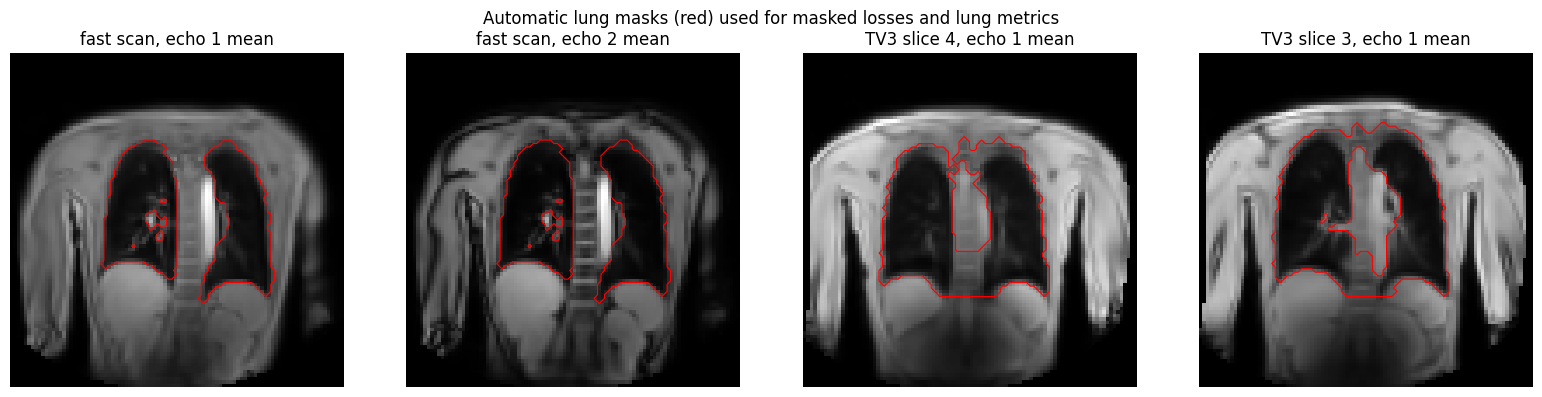

In [5]:
# ---- Lung mask (same algorithm as data_timing_analysis.ipynb) -----------------------------------
def lung_mask_from_mean(mean_img, max_centroid_row=62, max_row=None):
    """Automatic lung mask from a time-averaged *display-oriented* image.
    Steps: body (Otsu) -> dark regions inside the eroded body -> keep the two largest dark components whose centroid is
    above `max_centroid_row` (= above the diaphragm). `max_row` removes bowel/stomach gas below a given row."""
    body = mean_img > threshold_otsu(mean_img) * 0.5
    body = ndi.binary_fill_holes(ndi.binary_closing(body, iterations=2))
    lab, n = ndi.label(body)
    body = lab == (np.argmax(ndi.sum(body, lab, range(1, n + 1))) + 1)
    body = ndi.binary_fill_holes(body)
    thr = threshold_otsu(mean_img[body])
    dark = ndi.binary_erosion(body, iterations=3) & (mean_img < thr)
    if max_row is not None:
        dark[max_row:, :] = False
    dark = ndi.binary_opening(dark, iterations=1)
    lab, n = ndi.label(dark)
    sizes = ndi.sum(dark, lab, range(1, n + 1))
    centroids = ndi.center_of_mass(dark, lab, range(1, n + 1))
    cand = sorted([(s, i) for i, (s, c) in enumerate(zip(sizes, centroids)) if c[0] < max_centroid_row], reverse=True)
    mask = np.zeros_like(dark)
    for s, i in cand[:2]:
        if s > 0.15 * cand[0][0]:
            mask |= lab == (i + 1)
    return mask

def lung_mask(frames_e1, **kw):
    """Mask in *storage* orientation, computed on the echo-1 time average."""
    m_disp = lung_mask_from_mean(disp(frames_e1.mean(0)), **kw)
    return np.rot90(m_disp, -1).copy()

MASK_FAST = lung_mask(FAST[:, 0])
MASK_TV3S = {sl: lung_mask(TV3S[sl][:, 0], max_row=70) for sl in TV3_SLICES}   # TV3 subject: diaphragm at ~row 70 (display orientation)
MASK_TV3 = MASK_TV3S[TV3_PRIMARY]
print(f'lung mask pixels: fast {MASK_FAST.sum()}  ' + '  '.join(f'TV3 slice {sl} {MASK_TV3S[sl].sum()}' for sl in TV3_SLICES) + f'  (of {96*96})')

fig, ax = plt.subplots(1, 2 + len(TV3_SLICES), figsize=(4 * (2 + len(TV3_SLICES)), 4))
for a, img, m, title in [(ax[0], FAST[:, 0].mean(0), MASK_FAST, 'fast scan, echo 1 mean'),
                          (ax[1], FAST[:, 1].mean(0), MASK_FAST, 'fast scan, echo 2 mean')] + \
                         [(ax[2 + k], TV3S[sl][:, 0].mean(0), MASK_TV3S[sl], f'TV3 slice {sl}, echo 1 mean') for k, sl in enumerate(TV3_SLICES)]:
    a.imshow(disp(img), cmap='gray'); a.contour(disp(m), colors='r', linewidths=0.8); a.set_title(title); a.axis('off')
plt.suptitle('Automatic lung masks (red) used for masked losses and lung metrics'); plt.tight_layout(); plt.show()

In [6]:
# ---- Train / validation split (temporal, as before) and normalisation ---------------------------
N_TRAIN = int(FAST.shape[0] * Config().train_frac)
FAST_TRAIN, FAST_VAL = FAST[:N_TRAIN], FAST[N_TRAIN:]
print(f'train frames: {FAST_TRAIN.shape[0]}  ({FAST_TRAIN.shape[0]*FAST_DT_MS/1000:.1f} s)   val frames: {FAST_VAL.shape[0]}  ({FAST_VAL.shape[0]*FAST_DT_MS/1000:.1f} s)')

def resolve_norm_div(cfg, train_frames=FAST_TRAIN):
    """Normalisation divisor. 'fixed' keeps your 4096 (note: data max is ~1400, so images live in [0, 0.35]).
    'train_p999' uses the 99.9th percentile of the training frames of BOTH echoes - one shared number, so the
    echo-1/echo-2 ratio (and hence R2*) is unchanged by normalisation."""
    if cfg.normalize == 'fixed':
        return float(cfg.normalize_div)
    if cfg.normalize == 'train_p999':
        return float(np.percentile(train_frames, 99.9))
    raise ValueError(cfg.normalize)

def select_echo(frames, cfg):
    """(N, 2, H, W) -> (N, C, H, W) with C = 1 (echo 1 only) or 2."""
    return frames[:, :1] if cfg.echo_mode == 'e1' else frames

def prepare_test_frames(cfg, test_frames=TV3, train_frames=FAST_TRAIN):
    """Normalise the clinical scan with the training divisor. Optionally match its 99.9th percentile to the training
    data first, because scanner/protocol differences change the absolute intensity scale (see the checks table)."""
    x = test_frames.astype(np.float32)
    if cfg.test_intensity_match:
        x = x * (np.percentile(train_frames, 99.9) / np.percentile(x, 99.9))
    return select_echo(x, cfg) / resolve_norm_div(cfg, train_frames)

for n in ['fixed', 'train_p999']:
    print(f"normalize='{n}': divisor = {resolve_norm_div(replace(Config(), normalize=n)):.1f}")

train frames: 1600  (94.2 s)   val frames: 400  (23.6 s)
normalize='fixed': divisor = 4096.0


normalize='train_p999': divisor = 1067.9


In [7]:
class OEInterpDataset(Dataset):
    """Time-conditioned frame-interpolation dataset (generalisation of your InterpolationDataset).

    frames : (N, C, H, W) raw intensities, C = 1 or 2 echo channels (already selected by `select_echo`).
    One endpoint pair = frames (i, i + step). Train mode draws K random *distinct* interior targets per pair each time the
    pair is visited; val mode enumerates every interior target once (deterministic).

    Returns a dict:
        x     : (2C, H, W)   = [left frame channels, right frame channels]
        y     : (K, C, H, W) target frame(s)
        rel_t : (K,)         position of the target(s) in (0, 1) between the endpoints
        dt    : ()           endpoint interval / target_dt_ms   (= 26 for the fixed 26-gap)
        idx   : (K, 3)       [left, target, right] frame indices
    With C = 1, K = 1 and no augmentation this is sample-for-sample identical to the original dataset.
    """
    def __init__(self, frames, mode, step, target_dt_ms, norm_div, dt_ms, n_time_samples=1,
                 aug_flip=False, aug_intensity=0.0, aug_noise=0.0, max_pairs=0, seed=0):
        assert mode in ('train', 'val')
        self.frames, self.mode, self.step = frames, mode, int(step)
        self.K = int(n_time_samples) if mode == 'train' else 1
        self.norm_div, self.dt_norm = float(norm_div), dt_ms * step / target_dt_ms
        self.aug_flip, self.aug_intensity, self.aug_noise = aug_flip, aug_intensity, aug_noise
        self.pairs = [(i, i + self.step) for i in range(frames.shape[0] - self.step)]
        if max_pairs and max_pairs < len(self.pairs):
            rng = np.random.RandomState(seed)
            self.pairs = [self.pairs[j] for j in sorted(rng.choice(len(self.pairs), max_pairs, replace=False))]
        self.samples = [(i, k, j) for i, j in self.pairs for k in range(i + 1, j)] if mode == 'val' else None

    def __len__(self):
        return len(self.pairs) if self.mode == 'train' else len(self.samples)

    def _augment(self, left, right, targets):
        if self.aug_flip and np.random.rand() < 0.5:                      # same flip for every frame of the triplet
            left, right, targets = left[..., ::-1], right[..., ::-1], targets[..., ::-1]
        if self.aug_intensity > 0:                                         # same global scale for every frame
            s = np.random.uniform(1 - self.aug_intensity, 1 + self.aug_intensity)
            left, right, targets = left * s, right * s, targets * s
        if self.aug_noise > 0:                                             # independent noise per frame (acquisition noise)
            left = left + np.random.normal(0, self.aug_noise, left.shape)
            right = right + np.random.normal(0, self.aug_noise, right.shape)
            targets = targets + np.random.normal(0, self.aug_noise, targets.shape)
        return left, right, targets

    def __getitem__(self, idx):
        if self.mode == 'train':
            i, j = self.pairs[idx]
            ks = np.sort(np.random.choice(np.arange(i + 1, j), self.K, replace=False))
        else:
            i, k, j = self.samples[idx]; ks = np.array([k])
        left, right = self.frames[i] / self.norm_div, self.frames[j] / self.norm_div
        targets = self.frames[ks] / self.norm_div                                   # (K, C, H, W)
        if self.mode == 'train':
            left, right, targets = self._augment(left, right, targets)
        rel_t = (ks - i) / float(j - i)
        return dict(x=torch.tensor(np.ascontiguousarray(np.concatenate([left, right], 0)), dtype=torch.float32),
                    y=torch.tensor(np.ascontiguousarray(targets), dtype=torch.float32),
                    rel_t=torch.tensor(rel_t, dtype=torch.float32),
                    dt=torch.tensor(self.dt_norm, dtype=torch.float32),
                    idx=torch.tensor(np.stack([np.full_like(ks, i), ks, np.full_like(ks, j)], 1)))


def make_datasets(cfg):
    """Train / val datasets for a config (echo selection, normalisation, augmentation all from cfg)."""
    div = resolve_norm_div(cfg)
    common = dict(step=cfg.ds_ratio, target_dt_ms=cfg.target_dt_ms, norm_div=div, dt_ms=FAST_DT_MS)
    tr = OEInterpDataset(select_echo(FAST_TRAIN, cfg), 'train', n_time_samples=cfg.n_time_samples,
                         aug_flip=cfg.aug_flip, aug_intensity=cfg.aug_intensity, aug_noise=cfg.aug_noise,
                         max_pairs=cfg.max_train_pairs, seed=cfg.seed, **common)
    va = OEInterpDataset(select_echo(FAST_VAL, cfg), 'val', **common)
    return tr, va

# Quick check of both echo modes
for mode in ['e1', 'e1e2']:
    tr, va = make_datasets(replace(Config(), echo_mode=mode, n_time_samples=2))
    s = tr[0]
    print(f"echo_mode={mode}: {len(tr)} train pairs, {len(va)} val samples | x {tuple(s['x'].shape)}  y {tuple(s['y'].shape)}  "
          f"rel_t {s['rel_t'].numpy().round(3)}  dt {s['dt'].item():.2f}")

echo_mode=e1: 1574 train pairs, 9350 val samples | x (2, 96, 96)  y (2, 1, 96, 96)  rel_t [0.115 0.231]  dt 26.39
echo_mode=e1e2: 1574 train pairs, 9350 val samples | x (4, 96, 96)  y (2, 2, 96, 96)  rel_t [0.5   0.577]  dt 26.39


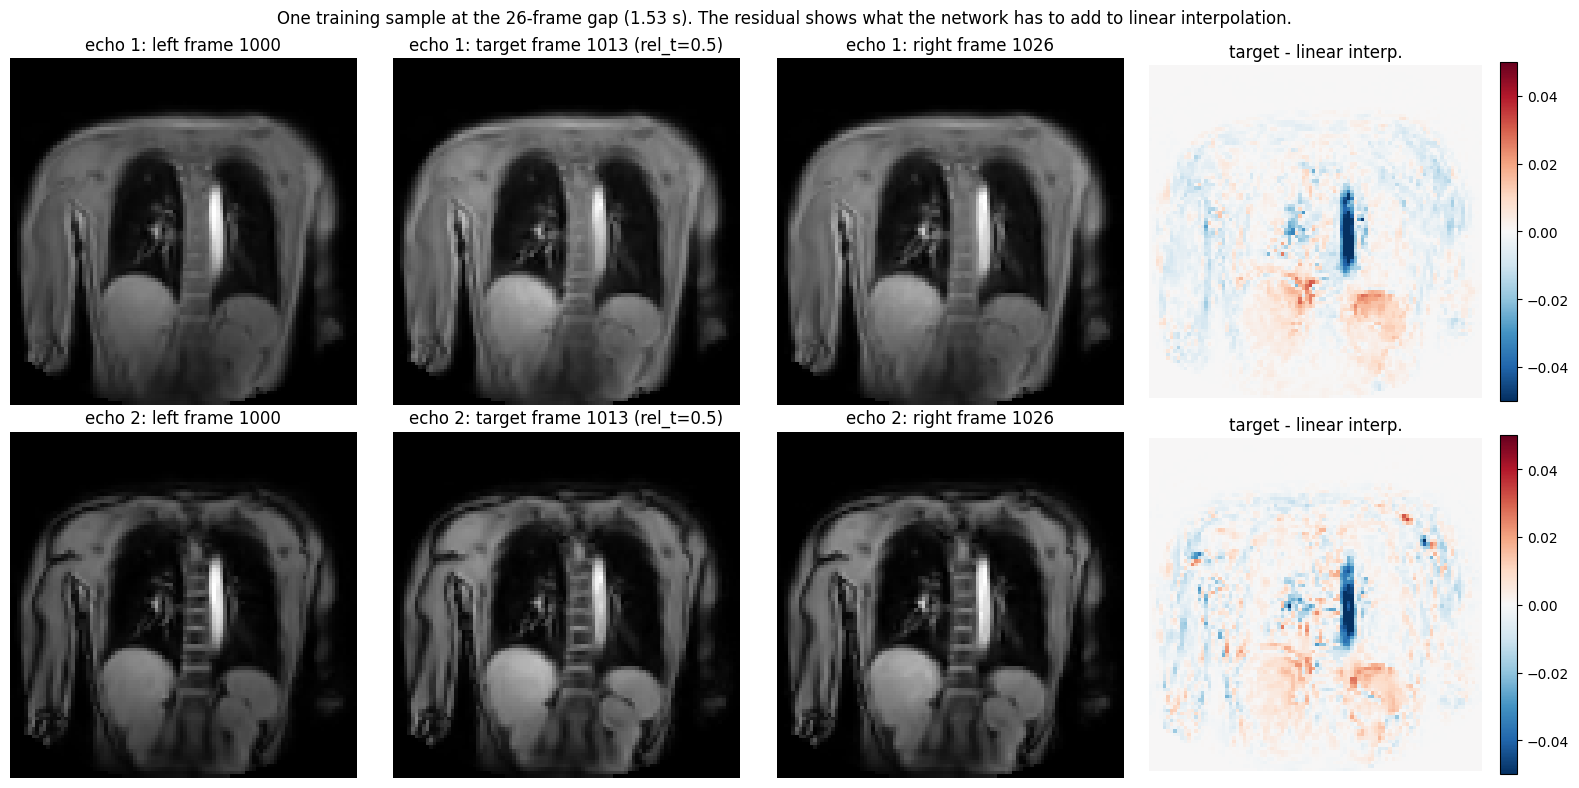

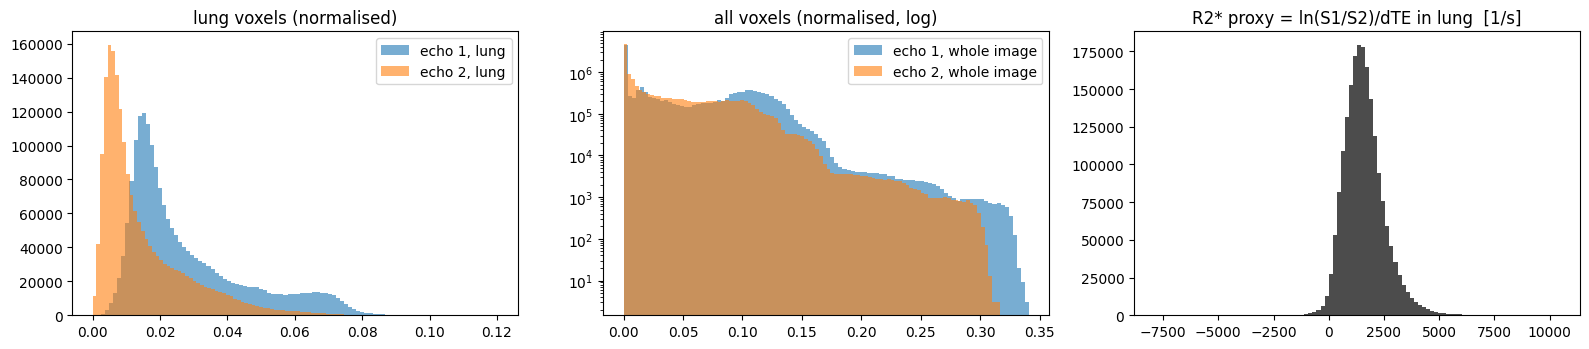

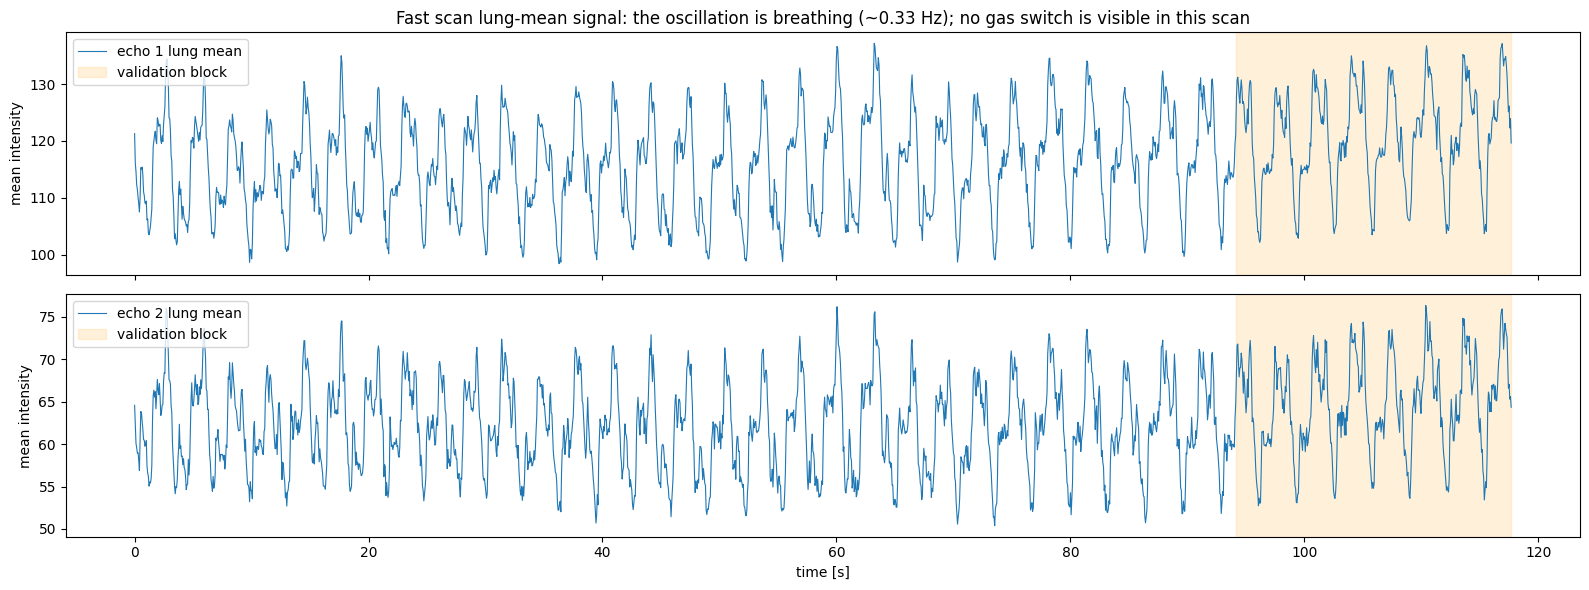

In [8]:
# ---- Visualisation 1: the two echoes, their ratio, and what changes between endpoint frames ------
cfg_vis = Config(echo_mode='e1e2')
div = resolve_norm_div(cfg_vis)
i, j = 1000, 1000 + cfg_vis.ds_ratio
k = i + cfg_vis.ds_ratio // 2
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(2):
    ax[c, 0].imshow(disp(FAST[i, c]) / div, cmap='gray'); ax[c, 0].set_title(f'echo {c+1}: left frame {i}')
    ax[c, 1].imshow(disp(FAST[k, c]) / div, cmap='gray'); ax[c, 1].set_title(f'echo {c+1}: target frame {k} (rel_t=0.5)')
    ax[c, 2].imshow(disp(FAST[j, c]) / div, cmap='gray'); ax[c, 2].set_title(f'echo {c+1}: right frame {j}')
    d = disp(FAST[k, c] - 0.5 * (FAST[i, c] + FAST[j, c])) / div
    im = ax[c, 3].imshow(d, cmap='RdBu_r', vmin=-0.05, vmax=0.05); ax[c, 3].set_title('target - linear interp.')
    plt.colorbar(im, ax=ax[c, 3], fraction=0.046)
for a in ax.ravel(): a.axis('off')
plt.suptitle(f'One training sample at the 26-frame gap ({cfg_vis.ds_ratio*FAST_DT_MS/1000:.2f} s). The residual shows what the network has to add to linear interpolation.')
plt.tight_layout(); plt.show()

# ---- Visualisation 2: intensity histograms per echo (normalised) ---------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for c in range(2):
    ax[0].hist((FAST_TRAIN[:, c][:, MASK_FAST] / div).ravel(), bins=100, alpha=0.6, label=f'echo {c+1}, lung')
    ax[1].hist((FAST_TRAIN[:, c] / div).ravel(), bins=100, alpha=0.6, label=f'echo {c+1}, whole image', log=True)
ax[0].set_title('lung voxels (normalised)'); ax[1].set_title('all voxels (normalised, log)'); ax[0].legend(); ax[1].legend()
ratio = np.log(np.clip(FAST_TRAIN[:, 0][:, MASK_FAST], 1, None) / np.clip(FAST_TRAIN[:, 1][:, MASK_FAST], 1, None)) / (1.2071 - 0.7099) * 1000
ax[2].hist(ratio.ravel(), bins=100, color='k', alpha=0.7); ax[2].set_title('R2* proxy = ln(S1/S2)/dTE in lung  [1/s]')
plt.tight_layout(); plt.show()

# ---- Visualisation 3: lung-mean curves of both echoes over the whole fast scan -------------------
t = np.arange(FAST.shape[0]) * FAST_DT_MS / 1000
fig, ax = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for c in range(2):
    ax[c].plot(t, FAST[:, c][:, MASK_FAST].mean(1), lw=0.8, label=f'echo {c+1} lung mean')
    ax[c].axvspan(t[N_TRAIN], t[-1], color='orange', alpha=0.15, label='validation block')
    ax[c].legend(loc='upper left'); ax[c].set_ylabel('mean intensity')
ax[1].set_xlabel('time [s]')
ax[0].set_title('Fast scan lung-mean signal: the oscillation is breathing (~0.33 Hz); no gas switch is visible in this scan')
plt.tight_layout(); plt.show()

## 2. Network architectures

What this section does:

* Keeps your existing classes **verbatim** (`DoubleConv`, `Down`, `Up`, `UNetInterpolation`, `MFIN_Base`, `MFIN`, `warp`, `tv_l1`,
  `mfin_loss_l1`). The only edit is removing the `print(...)` inside `MFIN.forward`.
* Adds `LinearInterp`, a zero-parameter module, so linear interpolation runs through the same training-free evaluation path.
* Adds the **multi-echo** variants: `UNetInterpolation` with `2C` in / `C` out, and `MFINMultiEcho(n_echo=C)`.
  In `MFINMultiEcho` the two echoes share one pair of flow fields and one blending mask, because both echoes are acquired
  in the same readout train and see the same physical motion; only the refinement head outputs `C` channels.
  With `n_echo=1` it has exactly the layer shapes of `MFIN`, so the 1-echo vs 2-echo comparison isolates the extra echo.
* `build_model(cfg)` and `run_model(...)` give every model the same interface: `pred, flows, warped, mask`.

Model table (1-echo = your baselines, 2-echo = new):

| `cfg.model` | echo_mode | time-conditioned | what it is |
|---|---|---|---|
| `linear` | e1 / e1e2 | yes (trivially) | `(1-t) * left + t * right` |
| `unet` | e1 | no (one frame per pair) | your `UNetInterpolation(2 -> 1)` |
| `mfin_base` | e1 | no (one frame per pair) | your `MFIN_Base`: flows + mask + refinement, no time input |
| `mfin` | e1 | yes | your `MFIN` with `rel_t`, `delta_t` channels |
| `unet_me` | e1e2 | no | `UNetInterpolation(4 -> 2)` (available, not in the current grid) |
| `mfin_me` | e1e2 | yes | `MFINMultiEcho(n_echo=2)` |

In [9]:
# ======================= your existing building blocks (unchanged) ===============================
class DoubleConv(nn.Module):
    """(Conv -> GroupNorm -> ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """Downscaling with maxpool then double conv"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_channels, out_channels))
    def forward(self, x):
        return self.block(x)


class Up(nn.Module):
    """Upscaling then double conv"""
    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
            self.conv = DoubleConv(in_channels, out_channels)
        else:
            self.up = nn.ConvTranspose2d(in_channels // 2, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)
        self.bilinear = bilinear
    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        return self.conv(torch.cat([x2, x1], dim=1))


class UNetInterpolation(nn.Module):
    """U-Net: (B, n_in, H, W) -> (B, n_out, H, W). Used directly as the frame predictor (unet, unet_me) and as the
    encoder / refinement network inside the MFIN models."""
    def __init__(self, n_channels_in=3, n_channels_out=1, base_filters=32, bilinear=True):
        super().__init__()
        self.n_channels_in, self.n_channels_out, self.bilinear = n_channels_in, n_channels_out, bilinear
        self.inc   = DoubleConv(n_channels_in, base_filters)
        self.down1 = Down(base_filters, base_filters * 2)
        self.down2 = Down(base_filters * 2, base_filters * 4)
        self.down3 = Down(base_filters * 4, base_filters * 8)
        factor = 2 if bilinear else 1
        self.down4 = Down(base_filters * 8, base_filters * 16 // factor)
        self.up1 = Up(base_filters * 16, base_filters * 8 // factor, bilinear)
        self.up2 = Up(base_filters * 8, base_filters * 4 // factor, bilinear)
        self.up3 = Up(base_filters * 4, base_filters * 2 // factor, bilinear)
        self.up4 = Up(base_filters * 2, base_filters, bilinear)
        self.outc = nn.Conv2d(base_filters, n_channels_out, kernel_size=1)
    def forward(self, x):
        x1 = self.inc(x); x2 = self.down1(x1); x3 = self.down2(x2); x4 = self.down3(x3); x5 = self.down4(x4)
        x = self.up1(x5, x4); x = self.up2(x, x3); x = self.up3(x, x2); x = self.up4(x, x1)
        return self.outc(x)


def warp(img, flow_px):
    """Backward-warp `img` (B, C, H, W) with a pixel-unit flow (B, 2, H, W) defined on the target grid.
    Works for any number of channels C, so both echoes can be warped with the same flow."""
    B, C, H, W = img.shape
    ys = torch.linspace(-1, 1, H, device=img.device)
    xs = torch.linspace(-1, 1, W, device=img.device)
    grid_y, grid_x = torch.meshgrid(ys, xs, indexing="ij")
    base_grid = torch.stack((grid_x, grid_y), dim=-1).unsqueeze(0).repeat(B, 1, 1, 1)
    dx = flow_px[:, 0] * (2.0 / max(W - 1, 1))
    dy = flow_px[:, 1] * (2.0 / max(H - 1, 1))
    sample_grid = base_grid + torch.stack((dx, dy), dim=-1)
    return F.grid_sample(img, sample_grid, mode="bilinear", padding_mode="border", align_corners=True)


def tv_l1(flow):
    """Total variation of a flow field: encourages spatially smooth motion."""
    dx = torch.abs(flow[:, :, :, 1:] - flow[:, :, :, :-1])
    dy = torch.abs(flow[:, :, 1:, :] - flow[:, :, :-1, :])
    return dx.mean() + dy.mean()


def mfin_loss_l1(Nt, Nt_m1, Nt_p1, F_t_to_tm1, F_t_to_tp1, lam_tv=1e-3):
    """Your warp loss: L1 of both warped neighbours to the target + TV smoothness of the flows."""
    Nt_hat_m1 = warp(Nt_m1, F_t_to_tm1)
    Nt_hat_p1 = warp(Nt_p1, F_t_to_tp1)
    recon = F.l1_loss(Nt_hat_m1, Nt) + F.l1_loss(Nt_hat_p1, Nt)
    reg = tv_l1(F_t_to_tm1) + tv_l1(F_t_to_tp1)
    return recon + lam_tv * reg, {"recon": recon.item(), "reg": reg.item()}


class MFIN_Base(nn.Module):
    """Your midpoint-only motion-field interpolation network (no time input)."""
    def __init__(self, in_ch=2, base=16, refine=True):
        super().__init__()
        self.use_refine = refine
        self.enc = UNetInterpolation(n_channels_in=in_ch, n_channels_out=base*2, base_filters=base, bilinear=True)
        self.mask_head = nn.Sequential(nn.Conv2d(base*2, base*2, 3, padding=1), nn.ReLU(inplace=True),
                                       nn.Conv2d(base*2, 1, 3, padding=1), nn.Sigmoid())
        self.head_tm1 = nn.Sequential(nn.Conv2d(base*2, base*2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base*2, 2, 3, padding=1))
        self.head_tp1 = nn.Sequential(nn.Conv2d(base*2, base*2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base*2, 2, 3, padding=1))
        if self.use_refine:
            self.refine = UNetInterpolation(n_channels_in=1, n_channels_out=1, base_filters=base, bilinear=True)

    def forward(self, x, return_mask=False):
        Nt_m1, Nt_p1 = x[:, 0:1, :, :], x[:, 1:2, :, :]
        f = self.enc(torch.cat([Nt_m1, Nt_p1], dim=1))
        mask = self.mask_head(f)
        F_t_to_tm1 = self.head_tm1(f)
        F_t_to_tp1 = self.head_tp1(f)
        if not self.use_refine:
            return F_t_to_tm1, F_t_to_tp1
        warped_tm1 = warp(Nt_m1, F_t_to_tm1)
        warped_tp1 = warp(Nt_p1, F_t_to_tp1)
        refined_input = mask * warped_tm1 + (1 - mask) * warped_tp1
        final_img = refined_input + self.refine(refined_input)
        if return_mask:
            return F_t_to_tm1, F_t_to_tp1, final_img, mask
        return F_t_to_tm1, F_t_to_tp1, final_img


class MFIN(nn.Module):
    """Your time-conditioned MFIN (1 echo). Inputs: left, right, rel_t map, delta_t map -> flows, mask, refined frame.
    Identical to gamma_transform.ipynb except that the debug print in forward() is removed."""
    def __init__(self, base=16, refine=True):
        super().__init__()
        self.use_refine = refine
        self.enc = UNetInterpolation(n_channels_in=4, n_channels_out=base * 2, base_filters=base, bilinear=True)
        self.mask_head = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                       nn.Conv2d(base * 2, 1, 3, padding=1), nn.Sigmoid())
        self.head_tm1 = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base * 2, 2, 3, padding=1))
        self.head_tp1 = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base * 2, 2, 3, padding=1))
        if self.use_refine:
            # warped_left, warped_right, mask, blended, rel_t, delta_t
            self.refine = UNetInterpolation(n_channels_in=6, n_channels_out=1, base_filters=base, bilinear=True)

    def forward(self, x, rel_t, delta_t, return_all=False):
        Nt_m1, Nt_p1 = x[:, 0:1], x[:, 1:2]
        B, _, H, W = Nt_m1.shape
        rel_t = rel_t.view(B, 1, 1, 1).expand(B, 1, H, W)
        delta_t = delta_t.view(B, 1, 1, 1).expand(B, 1, H, W)
        f = self.enc(torch.cat([Nt_m1, Nt_p1, rel_t, delta_t], dim=1))
        mask = self.mask_head(f)
        F_t_to_tm1 = self.head_tm1(f)
        F_t_to_tp1 = self.head_tp1(f)
        warped_tm1 = warp(Nt_m1, F_t_to_tm1)
        warped_tp1 = warp(Nt_p1, F_t_to_tp1)
        blended = mask * warped_tm1 + (1 - mask) * warped_tp1
        if not self.use_refine:
            if return_all:
                return F_t_to_tm1, F_t_to_tp1, blended, mask, warped_tm1, warped_tp1
            return F_t_to_tm1, F_t_to_tp1, blended
        residual = self.refine(torch.cat([warped_tm1, warped_tp1, mask, blended, rel_t, delta_t], dim=1))
        final_img = blended + residual
        if return_all:
            return F_t_to_tm1, F_t_to_tp1, final_img, mask, warped_tm1, warped_tp1
        return F_t_to_tm1, F_t_to_tp1, final_img

In [10]:
# ======================= new models ==============================================================
class LinearInterp(nn.Module):
    """Zero-parameter baseline: (1 - rel_t) * left + rel_t * right, for any number of echo channels."""
    def __init__(self, n_echo=1):
        super().__init__()
        self.n_echo = n_echo
    def forward(self, x, rel_t, delta_t=None):
        C = self.n_echo
        t = rel_t.view(-1, 1, 1, 1)
        return (1.0 - t) * x[:, :C] + t * x[:, C:]


class MFINMultiEcho(nn.Module):
    """Time-conditioned MFIN for C echo channels per frame.

    Design: both echoes come from the same readout train, so they share the SAME physical motion. Therefore
      * the encoder sees all 2C image channels (+ rel_t, delta_t) and predicts ONE pair of flows and ONE blending mask,
      * each echo is warped with those shared flows (warp() handles C channels),
      * the refinement U-Net takes [warped_left (C), warped_right (C), mask (1), blended (C), rel_t, delta_t] = 3C + 3 channels
        and outputs a C-channel residual.
    With n_echo = 1 every layer has the same shape as MFIN above (4-channel encoder input, 6-channel refinement input).
    """
    def __init__(self, n_echo=2, base=16, refine=True):
        super().__init__()
        self.n_echo, self.use_refine = n_echo, refine
        C = n_echo
        self.enc = UNetInterpolation(n_channels_in=2 * C + 2, n_channels_out=base * 2, base_filters=base, bilinear=True)
        self.mask_head = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                       nn.Conv2d(base * 2, 1, 3, padding=1), nn.Sigmoid())
        self.head_tm1 = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base * 2, 2, 3, padding=1))
        self.head_tp1 = nn.Sequential(nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU(inplace=True),
                                      nn.Conv2d(base * 2, 2, 3, padding=1))
        if refine:
            self.refine = UNetInterpolation(n_channels_in=3 * C + 3, n_channels_out=C, base_filters=base, bilinear=True)

    def forward(self, x, rel_t, delta_t, return_all=False):
        C = self.n_echo
        left, right = x[:, :C], x[:, C:]
        B, _, H, W = left.shape
        rel_t = rel_t.view(B, 1, 1, 1).expand(B, 1, H, W)
        delta_t = delta_t.view(B, 1, 1, 1).expand(B, 1, H, W)
        f = self.enc(torch.cat([left, right, rel_t, delta_t], dim=1))
        mask = self.mask_head(f)
        F_t_to_tm1 = self.head_tm1(f)
        F_t_to_tp1 = self.head_tp1(f)
        warped_tm1 = warp(left, F_t_to_tm1)            # shared flow applied to all echoes
        warped_tp1 = warp(right, F_t_to_tp1)
        blended = mask * warped_tm1 + (1 - mask) * warped_tp1
        if not self.use_refine:
            out = blended
        else:
            out = blended + self.refine(torch.cat([warped_tm1, warped_tp1, mask, blended, rel_t, delta_t], dim=1))
        if return_all:
            return F_t_to_tm1, F_t_to_tp1, out, mask, warped_tm1, warped_tp1
        return F_t_to_tm1, F_t_to_tp1, out


# ======================= unified construction and forward pass ===================================
TIME_CONDITIONED = {'linear', 'mfin', 'mfin_me'}       # models that receive rel_t. The others have no time input: they are trained on
                                                       # random in-gap targets and return the same frame for every t of a pair.
FLOW_MODELS = {'mfin_base', 'mfin', 'mfin_me'}         # models that output flows (-> warp loss applies)

def build_model(cfg):
    C = cfg.n_echo
    if cfg.model in ('unet', 'mfin_base', 'mfin'):
        assert C == 1, f"model '{cfg.model}' is the 1-echo baseline; use echo_mode='e1' (or model '{cfg.model}_me')"
    if cfg.model == 'linear':     return LinearInterp(C)
    if cfg.model == 'unet':       return UNetInterpolation(2, 1, cfg.unet_base_filters)
    if cfg.model == 'mfin_base':  return MFIN_Base(2, cfg.base_filters, cfg.refine)
    if cfg.model == 'mfin':       return MFIN(cfg.base_filters, cfg.refine)
    if cfg.model == 'unet_me':    return UNetInterpolation(2 * C, C, cfg.unet_base_filters)
    if cfg.model == 'mfin_me':    return MFINMultiEcho(C, cfg.base_filters, cfg.refine)
    raise ValueError(cfg.model)

def run_model(model, cfg, x, rel_t, dt):
    """Same output dict for every model: pred (B,C,H,W); flows / warped / mask are None for non-flow models."""
    out = dict(pred=None, flows=None, warped=None, mask=None)
    if cfg.model == 'linear':
        out['pred'] = model(x, rel_t, dt)
    elif cfg.model in ('unet', 'unet_me'):
        out['pred'] = model(x)
    elif cfg.model == 'mfin_base':
        f1, f2, pred, mask = model(x, return_mask=True)
        out.update(pred=pred, flows=(f1, f2), mask=mask, warped=(warp(x[:, :1], f1), warp(x[:, 1:], f2)))
    else:  # 'mfin', 'mfin_me'
        f1, f2, pred, mask, w1, w2 = model(x, rel_t, dt, return_all=True)
        out.update(pred=pred, flows=(f1, f2), mask=mask, warped=(w1, w2))
    return out

def n_params(m):
    return sum(p.numel() for p in m.parameters())

# Parameter table + a forward-pass shape check for every model
rows = []
for name, mode in [('linear', 'e1'), ('unet', 'e1'), ('mfin_base', 'e1'), ('mfin', 'e1'),
                   ('linear', 'e1e2'), ('unet_me', 'e1e2'), ('mfin_me', 'e1e2')]:
    cfg = Config(model=name, echo_mode=mode)
    m = build_model(cfg).eval()
    C = cfg.n_echo
    with torch.no_grad():
        o = run_model(m, cfg, torch.rand(2, 2 * C, 96, 96), torch.tensor([0.3, 0.7]), torch.tensor([26.0, 26.0]))
    rows.append(dict(model=name, echo_mode=mode, params_M=n_params(m) / 1e6, out_shape=tuple(o['pred'].shape),
                     time_conditioned=name in TIME_CONDITIONED, flows=o['flows'] is not None))
# sanity: MFINMultiEcho(1) has the same parameter count as MFIN
assert n_params(MFINMultiEcho(1)) == n_params(MFIN()), 'MFINMultiEcho(n_echo=1) should match MFIN layer-for-layer'
display(pd.DataFrame(rows).round(3))

,model,echo_mode,params_M,out_shape,time_conditioned,flows
0,linear,e1,0.000,"(2, 1, 96, 96)",True,False
1,unet,e1,3.350,"(2, 1, 96, 96)",False,False
2,mfin_base,e1,1.707,"(2, 1, 96, 96)",False,True
3,mfin,e1,1.708,"(2, 1, 96, 96)",True,True
4,linear,e1e2,0.000,"(2, 2, 96, 96)",True,False
5,unet_me,e1e2,3.351,"(2, 2, 96, 96)",False,False
6,mfin_me,e1e2,1.709,"(2, 2, 96, 96)",True,True


## 3. Loss functions

All terms are combined in one `CompositeLoss`; the weights come from the config and each term is logged separately per epoch,
so you can see which term does the work. Notation: `P` = prediction, `Y` = target, `L`/`R` = left/right endpoint frames,
`M` = lung mask (pixels), `C` = echo channels, all in normalised intensity units.

| term | formula | why |
|---|---|---|
| **Reconstruction** `w_recon` (original) | `mean(|P - Y|)` over the whole image | Standard L1 fidelity. Dominated by the body/background, which is 90 % of the pixels and barely moves. |
| **Warp + smoothness** `w_warp`, `lam_tv` (original, flow models) | `mean(|warp(L,F_l) - Y|) + mean(|warp(R,F_r) - Y|) + lam_tv * (TV(F_l) + TV(F_r))` | Supervises the two flow fields directly: each warped neighbour must already look like the target, and flows must be spatially smooth. Without it the refinement net can ignore the motion branch. |
| **Lung-masked L1** `w_lung` (new) | `sum(|P - Y| * M) / (sum(M) * C)` | The lung is ~10 % of the pixels but it is the only region that matters downstream (PSE, R2*). This term makes lung error count as much as whole-image error. |
| **Temporal consistency** `w_temporal` (new, needs `n_time_samples = 2`) | two targets `a < b` drawn from the same endpoint pair: `sum(|(P_b - P_a) - (Y_b - Y_a)| * M) / sum(M)` | The 25 synthesised frames between two real frames are produced by 25 independent forward passes. This term supervises the *change* between two of them, i.e. the local rate of change of the signal, so the synthesised curve is smooth and has the right slope instead of being 25 unrelated guesses. |
| **Enhancement** `w_enh` (new) | lung-mean change relative to the left endpoint: `| mean_M(P - L)/mean_M(L) - mean_M(Y - L)/mean_M(L) |`, per echo | PSE is a relative lung-mean signal change. This term asks the model to get that one scalar right for every synthesised frame; it is cheap and directly targets the downstream quantity. |
| **Echo-ratio** `w_ratio` (new, 2-echo only) | `sum(| ln(P1/P2) - ln(Y1/Y2) | * M) / sum(M)` | `R2* = ln(S1/S2) / dTE`. L1 on each echo separately does not guarantee their ratio; this term keeps the synthesised R2* faithful. |

Baselines use `w_recon = 1, w_warp = 0.5, lam_tv = 1e-3` and everything else 0, which is exactly your previous loss
`loss_recon + 0.5 * loss_warp`.

**Units and weights.** `recon`, `lung`, `temporal` and `warp` are all L1 in normalised intensity (typical trained values 0.002-0.005).
`enh` is a *relative* change (typical true changes 0.01-0.05) and `ratio` is an L1 on a log-ratio (typical lung value 0.1-0.3), so
they are 10-100x larger. The grid therefore uses `w_enh = 0.1` and `w_ratio = 0.01` so that no single term dominates; the
unweighted per-term curves plotted after training show whether that balance is right and should be tuned.

In [11]:
class CompositeLoss(nn.Module):
    """Weighted sum of the loss terms described above. Every term is computed; a weight of 0 just removes it from the total
    (it is still logged, which is useful to watch e.g. the lung error of a model trained on whole-image L1 only)."""
    def __init__(self, cfg, lung_mask):
        super().__init__()
        self.cfg = cfg
        m = torch.tensor(lung_mask.astype(np.float32))[None, None]          # (1, 1, H, W)
        self.register_buffer('mask', m)
        self.eps = 1e-3                                                      # floor for the log-ratio (normalised units)

    def masked_l1(self, a, b):
        """mean |a - b| over lung pixels (averaged over batch and channels)."""
        return (torch.abs(a - b) * self.mask).sum() / (self.mask.sum() * a.shape[0] * a.shape[1])

    def lung_mean(self, a):
        """(B, C, H, W) -> (B, C) mean over lung pixels."""
        return (a * self.mask).sum((2, 3)) / self.mask.sum()

    def forward(self, out, x, y, K):
        """out: dict from run_model on a flattened batch of B*K samples; x: (B*K, 2C, H, W); y: (B*K, C, H, W);
        K: number of target times per endpoint pair (consecutive rows of the flattened batch belong to the same pair)."""
        cfg, pred = self.cfg, out['pred']
        C = y.shape[1]
        left, right = x[:, :C], x[:, C:]
        terms = {}

        # 1) whole-image reconstruction
        terms['recon'] = F.l1_loss(pred, y)

        # 2) warp loss + flow smoothness (flow models only)
        if out['flows'] is not None:
            w1, w2 = out['warped']
            f1, f2 = out['flows']
            terms['warp'] = F.l1_loss(w1, y) + F.l1_loss(w2, y) + cfg.lam_tv * (tv_l1(f1) + tv_l1(f2))
        else:
            terms['warp'] = torch.zeros((), device=pred.device)

        # 3) lung-masked reconstruction
        terms['lung'] = self.masked_l1(pred, y)

        # 4) temporal consistency between the K targets of the same pair
        if K >= 2:
            p = pred.view(-1, K, *pred.shape[1:]); t = y.view(-1, K, *y.shape[1:])
            dp = p[:, 1:] - p[:, :-1]; dt_ = t[:, 1:] - t[:, :-1]              # (B, K-1, C, H, W)
            terms['temporal'] = self.masked_l1(dp.flatten(0, 1), dt_.flatten(0, 1))
        else:
            terms['temporal'] = torch.zeros((), device=pred.device)

        # 5) enhancement: lung-mean relative change w.r.t. the left endpoint
        mL = self.lung_mean(left).clamp_min(self.eps)
        terms['enh'] = torch.abs((self.lung_mean(pred) - mL) / mL - (self.lung_mean(y) - mL) / mL).mean()

        # 6) echo-ratio (log S1/S2) inside the lung, two-echo mode only
        if C == 2:
            lr_p = torch.log(pred[:, :1].clamp_min(self.eps) / pred[:, 1:].clamp_min(self.eps))
            lr_y = torch.log(y[:, :1].clamp_min(self.eps) / y[:, 1:].clamp_min(self.eps))
            terms['ratio'] = self.masked_l1(lr_p, lr_y)
        else:
            terms['ratio'] = torch.zeros((), device=pred.device)

        weights = dict(recon=cfg.w_recon, warp=cfg.w_warp, lung=cfg.w_lung, temporal=cfg.w_temporal, enh=cfg.w_enh, ratio=cfg.w_ratio)
        total = sum(weights[k] * v for k, v in terms.items() if weights[k] != 0)
        return total, {k: float(v) for k, v in terms.items()}

# Check every term on one batch of the 2-echo dataset with K = 2
cfg_t = Config(name='loss_check', model='mfin_me', echo_mode='e1e2', n_time_samples=2, w_lung=1, w_temporal=1, w_enh=1, w_ratio=1)
tr, _ = make_datasets(cfg_t)
b = next(iter(DataLoader(tr, batch_size=4)))
K = b['y'].shape[1]
x = b['x'].repeat_interleave(K, 0); y = b['y'].flatten(0, 1); rel = b['rel_t'].flatten(); dt = b['dt'].repeat_interleave(K)
m = build_model(cfg_t)
total, terms = CompositeLoss(cfg_t, MASK_FAST)(run_model(m, cfg_t, x, rel, dt), x, y, K)
print('total', round(float(total), 5), '| terms', {k: round(v, 5) for k, v in terms.items()})

total 10.39994 | terms {'recon': 0.21757, 'warp': 0.00742, 'lung': 0.13729, 'temporal': 0.00924, 'enh': 6.30911, 'ratio': 3.72303}


## 4. Training

One `train(cfg)` for every model:

* builds datasets, model, Adam optimiser and `CompositeLoss` from the config;
* flattens the `K` target times of each endpoint pair into the batch dimension (`x` repeated `K` times), so the models never
  need to know about `K` — only the loss does;
* validates every epoch on the **whole-image L1 of the final prediction** (same selection criterion as before) and also logs the
  lung L1; early-stops after `patience` epochs without improvement;
* saves the best weights to `checkpoints/<name>.pth` and the per-term history to `checkpoints/<name>_history.json`;
* `cfg.init_from` = path of a `.pth` to start from (fine-tuning / continued training). The earlier run's history (the
  `_history.json` next to that file) is prepended, so the history plot and `epochs_run` cover both stages;
* `get_or_train(cfg)` loads an existing checkpoint instead of retraining, unless `FORCE_RETRAIN`.

In [12]:
def flatten_targets(batch, device):
    """(B, K, ...) targets -> batch of B*K samples; x and dt are repeated so that rows k*K..k*K+K-1 share an endpoint pair."""
    x, y, rel, dt = batch['x'].to(device), batch['y'].to(device), batch['rel_t'].to(device), batch['dt'].to(device)
    K = y.shape[1]
    return x.repeat_interleave(K, 0), y.flatten(0, 1), rel.flatten(), dt.repeat_interleave(K), K


def train(cfg, verbose=True):
    seed_all(cfg.seed)
    tr, va = make_datasets(cfg)
    if SMOKE:   # evaluate on an evenly spaced subset of validation samples during the pipeline check
        va = Subset(va, np.linspace(0, len(va) - 1, 240).astype(int))
    tr_loader = DataLoader(tr, batch_size=cfg.batch_size, shuffle=True, drop_last=False, num_workers=0)
    va_loader = DataLoader(va, batch_size=32, shuffle=False, num_workers=0)

    model = build_model(cfg).to(DEVICE)
    prev = []                                            # history of the run we continue from (if any)
    if cfg.init_from:
        path = cfg.init_from if os.path.isabs(cfg.init_from) else os.path.join(PROJECT, cfg.init_from)
        if os.path.exists(path):
            model.load_state_dict(torch.load(path, map_location=DEVICE))
            hp = path[:-4] + '_history.json'
            if os.path.exists(hp):
                prev = json.load(open(hp))['history']
            if verbose: print(f"[{cfg.name}] initialised from {os.path.relpath(path, PROJECT)} ({len(prev)} earlier epochs)")
        else:
            print(f"[{cfg.name}] WARNING: init_from file not found ({path}) -> training from scratch")
    criterion = CompositeLoss(cfg, MASK_FAST).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    history, best, bad_epochs = [], float('inf'), 0
    if verbose:
        print(f"[{cfg.name}] model={cfg.model} echo={cfg.echo_mode} params={n_params(model)/1e6:.2f}M | "
              f"{len(tr)} train pairs x K={cfg.n_time_samples}, {len(va)} val samples, {cfg.epochs} epochs")

    for epoch in range(cfg.epochs):
        model.train(); t0 = time.time()
        sums, n = {}, 0
        for batch in tr_loader:
            x, y, rel, dt, K = flatten_targets(batch, DEVICE)
            opt.zero_grad()
            loss, terms = criterion(run_model(model, cfg, x, rel, dt), x, y, K)
            loss.backward(); opt.step()
            bs = batch['x'].shape[0]; n += bs
            sums['total'] = sums.get('total', 0) + float(loss) * bs
            for k, v in terms.items():
                sums[k] = sums.get(k, 0) + v * bs
        rec = {('train_' + k): v / n for k, v in sums.items()}

        model.eval(); v_recon = v_lung = 0.0; n = 0
        with torch.no_grad():
            for batch in va_loader:
                x, y, rel, dt, K = flatten_targets(batch, DEVICE)
                pred = run_model(model, cfg, x, rel, dt)['pred']
                bs = x.shape[0]; n += bs
                v_recon += F.l1_loss(pred, y).item() * bs
                v_lung += criterion.masked_l1(pred, y).item() * bs
        rec.update(epoch=len(prev) + epoch + 1, val_recon=v_recon / n, val_lung=v_lung / n, seconds=time.time() - t0,
                   finetune=bool(prev))
        history.append(rec)

        if rec['val_recon'] < best:
            best, bad_epochs = rec['val_recon'], 0
            torch.save(model.state_dict(), cfg.ckpt_path())
        else:
            bad_epochs += 1
        if verbose:
            print(f"  epoch {rec['epoch']:3d} | train {rec['train_total']:.5f} (recon {rec['train_recon']:.5f} lung {rec['train_lung']:.5f}) "
                  f"| val recon {rec['val_recon']:.5f} lung {rec['val_lung']:.5f} | best {best:.5f} | {rec['seconds']:.0f}s")
        if bad_epochs >= cfg.patience:
            if verbose: print('  early stopping')
            break

    history = prev + history
    json.dump(dict(config=asdict(cfg), history=history), open(cfg.history_path(), 'w'), indent=1)
    model.load_state_dict(torch.load(cfg.ckpt_path(), map_location=DEVICE))
    return model.eval(), history


def get_or_train(cfg):
    """Return (model, history). Order: trainable? -> existing checkpoint -> train (if RUN_TRAINING)."""
    model = build_model(cfg).to(DEVICE).eval()
    if cfg.model == 'linear':
        return model, []
    if os.path.exists(cfg.ckpt_path()) and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(cfg.ckpt_path(), map_location=DEVICE))
        hist = json.load(open(cfg.history_path()))['history'] if os.path.exists(cfg.history_path()) else []
        print(f'[{cfg.name}] loaded checkpoint {cfg.ckpt_path()} ({len(hist)} epochs)')
        return model, hist
    if not RUN_TRAINING:
        print(f'[{cfg.name}] no checkpoint and RUN_TRAINING=False -> skipped'); return None, []
    return train(cfg)


def plot_history(history, title):
    if not history: return
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    for k in [c for c in h.columns if c.startswith('train_') and c != 'train_total']:
        if h[k].abs().sum() > 0: ax[0].plot(h['epoch'], h[k], label=k.replace('train_', ''))
    ax[0].set_yscale('log'); ax[0].set_title('training loss terms (unweighted)'); ax[0].legend(fontsize=8); ax[0].set_xlabel('epoch')
    ax[1].plot(h['epoch'], h['val_recon'], label='val whole-image L1'); ax[1].plot(h['epoch'], h['val_lung'], label='val lung L1')
    ax[1].set_title('validation'); ax[1].legend(fontsize=8); ax[1].set_xlabel('epoch')
    if 'finetune' in h.columns and h['finetune'].any() and not h['finetune'].all():
        e0 = h.loc[h['finetune'], 'epoch'].iloc[0] - 0.5
        for a in ax: a.axvline(e0, color='k', ls='--', lw=0.8)
        ax[1].text(e0, ax[1].get_ylim()[1], ' fine-tuning starts', va='top', fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

## 5. Evaluation

Three levels, from generic to clinical:

**5a. Per-frame image metrics (fast validation block).** Every interior target of every 26-gap pair in the validation block
(9 350 samples; an evenly spaced subset in smoke mode): whole-image L1, lung L1, PSNR and SSIM, per echo, plus the metrics as a
function of the target position (`rel_t`), which shows how error grows towards the middle of the gap. The *lung L1 of echo 1*
is the headline number that is comparable across 1-echo and 2-echo models.

**5b. Dense 26x reconstruction of the validation block.** The validation block is subsampled to every 26th frame (= a 1.5 s
sequence), each model synthesises the 25 frames in between, and the result is compared with the real 58 ms frames:
lung-mean signal curves (truth vs synthesised), the breathing spectrum (how much of the ~0.33 Hz respiratory power is recovered),
pixel-wise temporal standard deviation maps, and for 2-echo models the R2\* proxy curve `ln(S1/S2)/dTE`.

**5c. Downstream OE-MRI quantities on TV3 (clinical 1.54 s scan).** Each model upsamples the real protocol scan 26x, for every
slice in `TV3_SLICES` (primary = slice 4, control = slice 3; metric columns carry the suffix `_s4` / `_s3`). From the original
("coarse") and the upsampled ("dense") sequence we compute the **PSE map** `(mean(O2 plateau) - mean(air)) / mean(air) x 100 %`,
two lung summaries of it (`pse_lung` = PSE of the lung-mean curve; `pse_vox` = mean of the voxel-wise map, which weights dark
voxels more), and for 2-echo models the **dR2\* map** = R2\* of the time-averaged echo images over the O2 plateau minus the
same over the air window (R2\* = `ln(S1/S2)/dTE`, in 1/s; signals are averaged before the log because per-voxel log-ratios of
single frames are dominated by near-zero echo-2 voxels), with its lung-ROI value and the coarse-vs-dense map difference.
The **wash-in time constant** (exponential fit to the smoothed lung-mean curve during the oxygen phase) is kept as a diagnostic only.
No dense ground truth exists for TV3, and the dense sequence contains the real frames, so this is a **consistency and plausibility
check** (does upsampling preserve PSE and dR2\*? does the curve look physiological?), not an accuracy measurement.

### Metric glossary: what each number is, how it is computed, what it means clinically

Standard image metrics (L1, PSNR, SSIM) are not repeated here. "Dense" always means the 26x synthesised sequence; "truth" means the
real 58 ms frames of the validation block. Everything lung-related uses the automatic lung mask.

| metric (registry column) | what it is | how it is computed | what it implies |
|---|---|---|---|
| `l1_lung_e1`, `l1_lung_mid_e1` | Lung-only L1 error of echo 1; `mid` = targets near the centre of the gap (`0.4 <= rel_t <= 0.6`) | mean of abs(pred - truth) over lung-mask pixels, averaged over validation samples | Error where the clinical signal lives. The `mid` value is the hardest case (farthest from both real frames). Headline number for comparing 1-echo and 2-echo models. |
| `lung_mean_abs_err_e1` | Relative error of the lung-mean brightness of a synthesised frame | abs(mean_lung(pred) - mean_lung(truth)) / mean_lung(truth), averaged over samples | PSE is built from the lung-mean brightness; a 1 % error here is a 1 % bias in enhancement for that frame. |
| `curve_rmse_e1` | Relative RMSE of the lung-mean time curve | compute mean lung brightness per frame for dense and truth, take differences at synthesised frames, root-mean-square, divide by the mean lung brightness | Overall fidelity of the lung signal over time (level and oscillation together). 0.02 = 2 % average deviation. |
| `breath_power_ratio_e1` | Fraction of the breathing oscillation recovered | detrend both lung-mean curves with a 5 s moving average, Fourier transform, sum the power between 0.2 and 0.5 Hz, divide dense by truth | 1 = the breathing rhythm is fully recovered; much less than 1 = output is too smooth (linear interpolation gives ~0.2); much more than 1 = invented oscillation. The 1.54 s protocol cannot see breathing (Nyquist limit), so recovering it is the whole point of upsampling. |
| `tstd_ratio_e1` | How much the synthesised pixels fluctuate over time compared with real pixels | per lung pixel, standard deviation over time; average over the lung; divide dense by truth | 1 = realistic amount of motion/dynamics; < 1 = static or blurred output; > 1 = flicker/noise added by the model. Complements the power ratio, which only looks at one curve. |
| `r2s_curve_rmse` (2-echo only) | Error of the lung-ROI R2* curve | R2* per frame = ln(mean_lung S_echo1 / mean_lung S_echo2) / (TE2 - TE1) [1/s] (ROI averaged before the log); RMSE between dense and truth at synthesised frames | R2* is the ventilation-sensitive quantity in the paper (gaseous O2 raises R2*). A model that gets each echo roughly right but their ratio wrong would still fail this. |
| `pse_lung_*` | Percent signal enhancement of the lung ROI | PSE = (mean brightness during the O2 plateau - mean during air) / mean during air x 100, computed on the lung-mean curve; air window = TV3 frames 10-60, O2 window = last 40 frames of the O2 phase | The paper's primary oxygen measure; negative here because oxygen shortens T2* and darkens the lung. `coarse` uses the real 1.54 s frames, `dense` the synthesised 26x sequence; the two should agree if upsampling is faithful. |
| `pse_vox_*`, `pse_map_mad_*` | Voxel-wise PSE map summary and the mean absolute difference between coarse and dense maps inside the lung | same PSE formula per voxel (baseline floored at 20 % of the lung mean to avoid divisions by ~0); `vox` = mean of the map over the lung, `mad` = mean abs(map_dense - map_coarse) | Regional version of PSE, which is what is shown as maps clinically. `mad` in percentage points tells you how much the upsampling changes the map; for reference the physiological effect itself is ~4-8 %. |
| `dr2s_roi_*`, `dr2s_map_mad_*` (2-echo only) | Oxygen-induced change of R2* in the lung [1/s]: the paper's ventilation measure | dR2* map = R2* of the time-averaged echo images over the O2 plateau - R2* of the time-averaged images over the air window (R2* = ln(S1/S2)/dTE); `roi` = mean of the lung-ROI R2* curve over the O2 plateau - mean over the air window, `mad` = mean abs(map_dense - map_coarse) in the lung | Positive (oxygen raises R2*). Reference values here: ~+31 /s on slice 4, ~+5 /s on slice 3. `coarse` and `dense` should agree; `mad` tells how much upsampling alters the regional map. Unlike PSE it is insensitive to density changes. |
| `washin_tau_*` (diagnostic only) | Wash-in time constant (seconds) of the oxygen response | smooth the lung-mean curve with a 5 s moving average, fit S(t) = S0 + A (1 - exp(-(t - t_on)/tau)) over the O2 phase only, multi-start fit, tau bounded to [1, 300] s | How quickly oxygen reaches the lung, a ventilation-efficiency marker in the paper. 300 means no saturating wash-in could be fitted (true for the ROI curve of this TV3 slice). Only differences between `coarse` and `dense` are informative here. |

All TV3 columns carry a slice suffix (`_s4` primary, `_s3` control).

**Caveat.** PSE, R2* and wash-in follow the paper's definitions but are re-implemented here in simplified form (no density
correction, ROI-level wash-in). The curve RMSE, breathing-power ratio and temporal-std ratio are project-specific diagnostics
for model development, not established clinical metrics. For a publication the physiological numbers should be reproduced with
the clinical processing pipeline.

In [13]:
# ---- 5a. per-frame image metrics ----------------------------------------------------------------
@torch.no_grad()
def predict(model, cfg, x, rel, dt, bs=64):
    """Batched inference on numpy/tensor inputs -> numpy prediction (N, C, H, W)."""
    x = torch.as_tensor(x, dtype=torch.float32); rel = torch.as_tensor(rel, dtype=torch.float32); dt = torch.as_tensor(dt, dtype=torch.float32)
    preds = []
    for s in range(0, x.shape[0], bs):
        o = run_model(model, cfg, x[s:s+bs].to(DEVICE), rel[s:s+bs].to(DEVICE), dt[s:s+bs].to(DEVICE))
        preds.append(o['pred'].cpu())
    return torch.cat(preds).numpy()


def evaluate_val(model, cfg, max_samples=None):
    """Per-sample metrics over the validation enumeration. Returns a DataFrame with one row per (sample, echo)."""
    _, va = make_datasets(cfg)
    n_total = len(va)
    sel = np.arange(n_total) if max_samples is None or max_samples >= n_total else np.linspace(0, n_total - 1, max_samples).astype(int)
    loader = DataLoader(Subset(va, sel), batch_size=64, shuffle=False)
    rows = []
    with torch.no_grad():
        for batch in loader:
            x, y, rel, dt, K = flatten_targets(batch, DEVICE)
            pred = run_model(model, cfg, x, rel, dt)['pred'].cpu().numpy(); y = y.cpu().numpy(); x = x.cpu().numpy()
            idx = batch['idx'].numpy()[:, 0]
            for b in range(pred.shape[0]):
                for c in range(y.shape[1]):
                    t, p = y[b, c], pred[b, c]
                    dr = t.max() - t.min()
                    rows.append(dict(left=int(idx[b, 0]), target=int(idx[b, 1]), right=int(idx[b, 2]), rel_t=float(rel[b]), echo=c + 1,
                                     l1=np.abs(p - t).mean(), l1_lung=np.abs(p - t)[MASK_FAST].mean(),
                                     psnr=peak_signal_noise_ratio(t, p, data_range=dr),
                                     ssim=structural_similarity(t, p, data_range=dr),
                                     lung_mean_err=(p[MASK_FAST].mean() - t[MASK_FAST].mean()) / t[MASK_FAST].mean()))
    return pd.DataFrame(rows)


def summarize_val(df):
    """Headline numbers: per echo, all rel_t and the hardest middle positions (0.4 <= rel_t <= 0.6)."""
    out = {}
    for c, g in df.groupby('echo'):
        mid = g[(g.rel_t >= 0.4) & (g.rel_t <= 0.6)]
        out.update({f'l1_e{c}': g.l1.mean(), f'l1_lung_e{c}': g.l1_lung.mean(), f'psnr_e{c}': g.psnr.mean(), f'ssim_e{c}': g.ssim.mean(),
                    f'l1_lung_mid_e{c}': mid.l1_lung.mean(), f'lung_mean_abs_err_e{c}': g.lung_mean_err.abs().mean()})
    return out

In [14]:
# ---- 5b. dense reconstruction and physiological curve metrics -----------------------------------
@torch.no_grad()
def reconstruct_dense(model, cfg, coarse, ratio, dt_norm):
    """coarse: (N, C, H, W) normalised frames at the coarse rate -> dense ((N-1)*ratio + 1, C, H, W).
    Real frames are copied to positions 0, ratio, 2*ratio, ...; the ratio-1 frames in between are synthesised."""
    N, C, H, W = coarse.shape
    dense = np.zeros(((N - 1) * ratio + 1, C, H, W), dtype=np.float32)
    dense[::ratio] = coarse
    pairs = [(i, s) for i in range(N - 1) for s in range(1, ratio)]
    x = np.stack([np.concatenate([coarse[i], coarse[i + 1]], 0) for i, s in pairs])
    rel = np.array([s / ratio for i, s in pairs], dtype=np.float32)
    pred = predict(model, cfg, x, rel, np.full(len(pairs), dt_norm, dtype=np.float32))
    for (i, s), p in zip(pairs, pred):
        dense[i * ratio + s] = p
    return dense

def lung_curve(frames, mask):
    """(N, C, H, W) -> (N, C) lung-mean curve."""
    return frames[:, :, mask].mean(-1)

def r2star_of(s1, s2, te1=0.7099, te2=1.2071, eps=1e-3):
    """R2* proxy [1/s] from echo-1 and echo-2 intensities of the same shape: ln(S1/S2) / dTE  (dTE in ms -> x1000)."""
    return np.log(np.clip(s1, eps, None) / np.clip(s2, eps, None)) / (te2 - te1) * 1000.0

def r2star_curve(frames, mask, **kw):
    """Lung-ROI R2* curve [1/s]: R2* of the lung-mean echo-1 and echo-2 signals of each frame. The ROI is averaged *before*
    the log: per-voxel log-ratios are dominated by near-zero echo-2 voxels and give a biased, very noisy mean."""
    c = lung_curve(frames, mask)
    return r2star_of(c[:, 0], c[:, 1], **kw)

def dr2star_map(frames, air, o2, **kw):
    """dR2* map [1/s] = R2* of the time-averaged echo images over the O2 window minus the same over the air window
    (half-open frame ranges). Averaging ~50 frames before the log raises the SNR of the voxel-wise estimate."""
    a = frames[air[0]:air[1]].mean(0); o = frames[o2[0]:o2[1]].mean(0)
    return r2star_of(o[0], o[1], **kw) - r2star_of(a[0], a[1], **kw)

def band_power(curve, dt_s, band=(0.2, 0.5)):
    """Power of a detrended curve in a frequency band (breathing is ~0.33 Hz here)."""
    c = curve - ndi.uniform_filter1d(curve, int(round(5 / dt_s)), mode='nearest')      # remove slow drift (> 5 s)
    f = np.fft.rfftfreq(len(c), dt_s); P = np.abs(np.fft.rfft(c)) ** 2
    return P[(f >= band[0]) & (f <= band[1])].sum()

def evaluate_dense_val(model, cfg):
    """Upsample the subsampled validation block 26x and compare with the real dense frames."""
    div = resolve_norm_div(cfg); ratio = cfg.ds_ratio
    truth = select_echo(FAST_VAL, cfg) / div
    coarse = truth[::ratio]
    dense = reconstruct_dense(model, cfg, coarse, ratio, FAST_DT_MS * ratio / cfg.target_dt_ms)
    truth = truth[:dense.shape[0]]
    ct, cd = lung_curve(truth, MASK_FAST), lung_curve(dense, MASK_FAST)
    interior = np.arange(dense.shape[0]) % ratio != 0
    m = {}
    for c in range(truth.shape[1]):
        m[f'curve_rmse_e{c+1}'] = np.sqrt(((cd[interior, c] - ct[interior, c]) ** 2).mean()) / ct[:, c].mean()   # relative
        m[f'breath_power_ratio_e{c+1}'] = band_power(cd[:, c], FAST_DT_MS / 1000) / band_power(ct[:, c], FAST_DT_MS / 1000)
        m[f'tstd_ratio_e{c+1}'] = dense[:, c][:, MASK_FAST].std(0).mean() / truth[:, c][:, MASK_FAST].std(0).mean()
    if truth.shape[1] == 2:
        rt, rd = r2star_curve(truth, MASK_FAST), r2star_curve(dense, MASK_FAST)
        m['r2s_curve_rmse'] = np.sqrt(((rd[interior] - rt[interior]) ** 2).mean())
    return m, dict(truth=truth, dense=dense, curve_truth=ct, curve_dense=cd)

In [15]:
# ---- 5c. PSE and wash-in on the clinical scan (consistency check) ---------------------------------
def pse_map(frames, air, o2, mask):
    """Percent signal enhancement map from frame-index windows (half-open). Negative for T2*-weighted OE-MRI.
    The baseline is floored at 20 % of the lung-mean baseline so that near-zero voxels cannot explode the percentage."""
    base = frames[air[0]:air[1]].mean(0); enh = frames[o2[0]:o2[1]].mean(0)
    floor = 0.2 * base[mask].mean()
    return (enh - base) / np.clip(base, floor, None) * 100.0

def pse_lung(curve, air, o2):
    """Lung-ROI PSE from the lung-mean curve (ratio of window means), as in the paper's ROI analysis."""
    b, e = curve[air[0]:air[1]].mean(), curve[o2[0]:o2[1]].mean()
    return (e - b) / b * 100.0

def washin_fit(t, s, t_on, t_off, smooth_s=5.0):
    """Fit S(t) = S0 + A * (1 - exp(-(t - t_on) / tau)) on the O2 phase t_on <= t < t_off only (the wash-out after
    t_off must NOT be included or the fit degenerates). The curve is first smoothed with a `smooth_s`-second moving
    average to suppress the breathing zig-zag, so coarse and dense curves are fitted on the same footing.
    Returns (S0, A, tau) or NaNs. tau is bounded to [1, 300] s; 300 means 'no saturating wash-in found'."""
    win = max(int(round(smooth_s / np.median(np.diff(t)))), 1)
    s = ndi.uniform_filter1d(s, win, mode='nearest')
    sel = (t >= t_on) & (t < t_off)
    def f(tt, S0, A, tau): return S0 + A * (1 - np.exp(-(tt - t_on) / tau))
    best, best_res = np.array([np.nan, np.nan, np.nan]), np.inf
    for tau0 in (5.0, 15.0, 30.0, 60.0, 120.0):                       # multi-start: the problem is shallow for a 1-2 % drop
        try:
            p0 = [s[sel][:3].mean(), s[sel][-5:].mean() - s[sel][:3].mean(), tau0]
            popt, _ = curve_fit(f, t[sel], s[sel], p0=p0, bounds=([-np.inf, -np.inf, 1.0], [np.inf, np.inf, 300.0]), maxfev=10000)
            res = ((f(t[sel], *popt) - s[sel]) ** 2).mean()
            if res < best_res:
                best, best_res = popt, res
        except Exception:
            pass
    return best

def evaluate_tv3(model, cfg, frame_range=None, sl=None):
    """Upsample one TV3 slice (both echoes if echo_mode='e1e2') 26x and compare PSE (and dR2* for 2-echo models) between the
    coarse (real 1.54 s) and dense (26x synthesised) sequences. Metric names carry no slice suffix; the caller adds `_s{sl}`."""
    ratio = cfg.ds_ratio
    sl = cfg.test_slice if sl is None else sl
    MASK_TV3 = MASK_TV3S[sl]                                        # local name shadows the primary-slice global on purpose
    frames = prepare_test_frames(cfg, TV3S[sl])
    lo, hi = frame_range if frame_range else (0, frames.shape[0])
    coarse = frames[lo:hi]
    dense = reconstruct_dense(model, cfg, coarse, ratio, TV3_DT_MS / cfg.target_dt_ms)
    # gas windows in coarse indices (relative to lo); plateau = last 60 s of the O2 phase, baseline = air frames 10..60
    air = (max(10 - lo, 0), TV3_GAS['o2'][0] - lo); o2 = (TV3_GAS['o2'][1] - 40 - lo, TV3_GAS['o2'][1] - lo)
    air_d, o2_d = (air[0] * ratio, air[1] * ratio), (o2[0] * ratio, o2[1] * ratio)
    t_c = (np.arange(coarse.shape[0]) + lo) * TV3_DT_MS / 1000
    t_d = (np.arange(dense.shape[0]) / ratio + lo) * TV3_DT_MS / 1000
    cc, cd = lung_curve(coarse, MASK_TV3), lung_curve(dense, MASK_TV3)
    m, maps = {}, {}
    for c in range(coarse.shape[1]):
        pc, pd_ = pse_map(coarse[:, c], air, o2, MASK_TV3), pse_map(dense[:, c], air_d, o2_d, MASK_TV3)
        maps[f'pse_coarse_e{c+1}'], maps[f'pse_dense_e{c+1}'] = pc, pd_
        m[f'pse_lung_coarse_e{c+1}'] = pse_lung(cc[:, c], air, o2); m[f'pse_lung_dense_e{c+1}'] = pse_lung(cd[:, c], air_d, o2_d)   # PSE of the ROI-mean curve
        m[f'pse_vox_coarse_e{c+1}'] = pc[MASK_TV3].mean(); m[f'pse_vox_dense_e{c+1}'] = pd_[MASK_TV3].mean()                       # mean of the voxel-wise PSE map (weights dark voxels more)
        m[f'pse_map_mad_e{c+1}'] = np.abs(pc - pd_)[MASK_TV3].mean()                          # mean abs. difference of PSE maps in the lung
        t_on, t_off = TV3_GAS['o2'][0] * TV3_DT_MS / 1000, min(TV3_GAS['o2'][1], hi) * TV3_DT_MS / 1000
        tau_c = washin_fit(t_c, cc[:, c], t_on, t_off)[2]
        tau_d = washin_fit(t_d, cd[:, c], t_on, t_off)[2]
        m[f'washin_tau_coarse_e{c+1}'], m[f'washin_tau_dense_e{c+1}'] = tau_c, tau_d
    if coarse.shape[1] == 2:                                        # dR2*: only possible with both echoes
        rc, rd = r2star_curve(coarse, MASK_TV3), r2star_curve(dense, MASK_TV3)
        m['dr2s_roi_coarse'] = rc[o2[0]:o2[1]].mean() - rc[air[0]:air[1]].mean()
        m['dr2s_roi_dense'] = rd[o2_d[0]:o2_d[1]].mean() - rd[air_d[0]:air_d[1]].mean()
        dc, dd = dr2star_map(coarse, air, o2), dr2star_map(dense, air_d, o2_d)
        maps['dr2s_coarse'], maps['dr2s_dense'] = dc, dd
        m['dr2s_map_mad'] = np.abs(dc - dd)[MASK_TV3].mean()
        maps['r2s_curve_coarse'], maps['r2s_curve_dense'] = rc, rd
    return m, dict(slice=sl, mask=MASK_TV3, coarse=coarse, dense=dense, t_coarse=t_c, t_dense=t_d, curve_coarse=cc, curve_dense=cd, maps=maps)

## 6. Experiment grid and results registry

Each entry below is a full experiment. Groups:

* **Baselines (1 echo)** – `linear_e1`, `unet_e1`, `mfin_base_e1` (100 epochs, early stopping with patience 10) and
  `mfin_e1_scratch`: the time-conditioned MFIN with the original loss, trained from scratch for a fixed 100 epochs. This is the
  control for the loss ablation.
* **Loss ablations on the 1-echo time-conditioned MFIN** – `mfin_e1_lung` (+lung), `mfin_e1_lung_temp` (+lung+temporal),
  `mfin_e1_full` (+lung+temporal+enh, +augmentation). These are **fine-tuned**: they start from the first-pass checkpoints in
  `checkpoints/stage1_100ep/` (100 epochs with early stopping) and train for another fixed 100 epochs (`init_from`, `patience=100`).
* **Two echoes** – `linear_e1e2` and `mfin_me_e1e2_full` (all loss terms incl. echo ratio), fine-tuned the same way.
  `mfin_e1_full` vs `mfin_me_e1e2_full` isolates the second echo (identical losses, augmentation and schedule).

Removed from the grid: the April 2026 checkpoint (`mfin_e1`), `unet_me_e1e2` and `mfin_me_e1e2`; their rows are dropped from the
registry at the end of this section.

Every run appends one row (config + all metrics) to `results/registry.csv` (`registry_smoke.csv` in smoke mode). To add an
experiment, append a `Config(...)` and rerun this section; finished ones are loaded from disk.

linear_e1: model=linear echo=e1 losses=w_recon=1.0, w_warp=0.5


  -> lung L1 e1 0.00358 | curve RMSE e1 0.0638 | breath power ratio 0.18 | TV3 s4 PSE coarse/dense -2.78/-2.81 % | 6s
unet_e1: model=unet echo=e1 losses=w_recon=1.0
[unet_e1] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\unet_e1.pth (29 epochs)


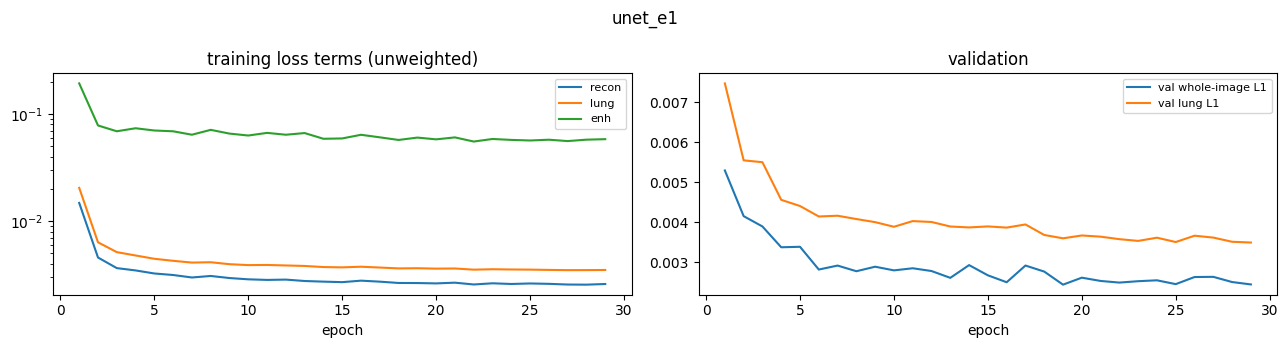

  -> lung L1 e1 0.00360 | curve RMSE e1 0.0554 | breath power ratio 0.23 | TV3 s4 PSE coarse/dense -2.78/-1.64 % | 21s
mfin_base_e1: model=mfin_base echo=e1 losses=w_recon=1.0, w_warp=0.5
[mfin_base_e1] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_base_e1.pth (53 epochs)


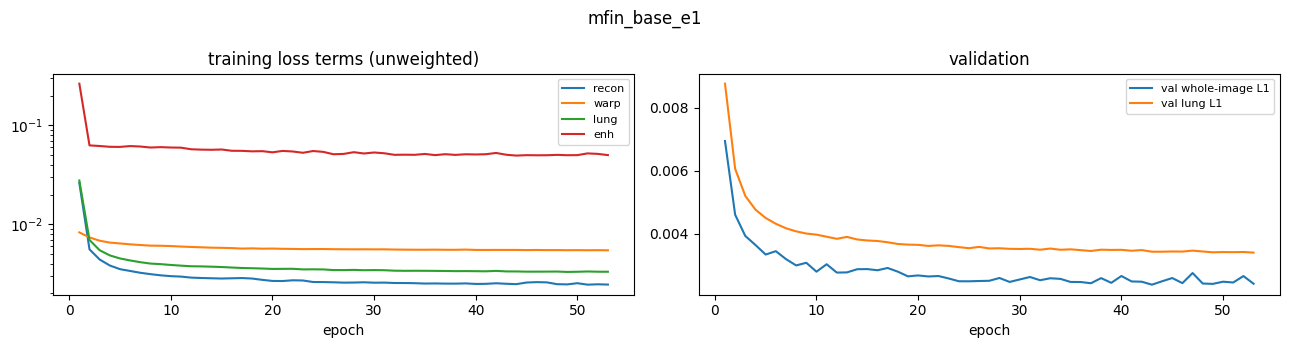

  -> lung L1 e1 0.00344 | curve RMSE e1 0.0533 | breath power ratio 0.32 | TV3 s4 PSE coarse/dense -2.78/-2.62 % | 24s
mfin_e1_scratch: model=mfin echo=e1 losses=w_recon=1.0, w_warp=0.5
[mfin_e1_scratch] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_e1_scratch.pth (100 epochs)


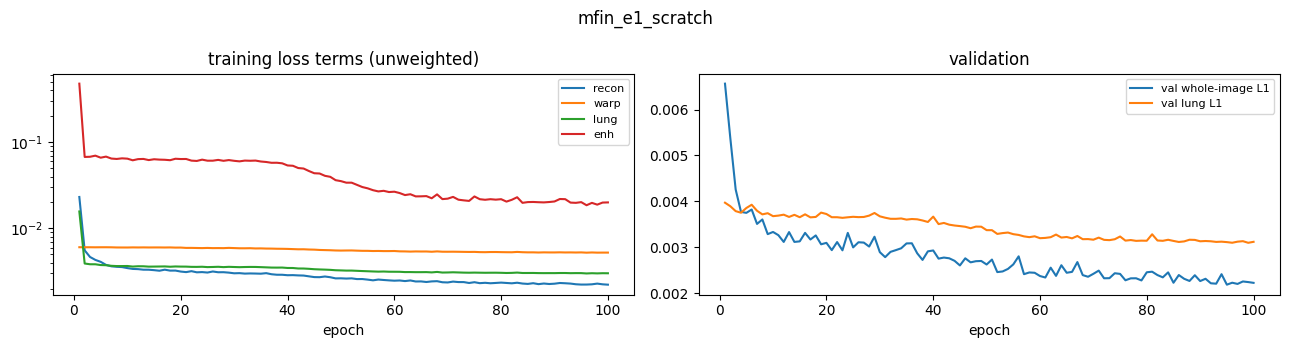

  -> lung L1 e1 0.00311 | curve RMSE e1 0.0229 | breath power ratio 0.80 | TV3 s4 PSE coarse/dense -2.78/-2.87 % | 24s
mfin_e1_lung: model=mfin echo=e1 losses=w_recon=1.0, w_warp=0.5, w_lung=1.0
[mfin_e1_lung] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_e1_lung.pth (141 epochs)


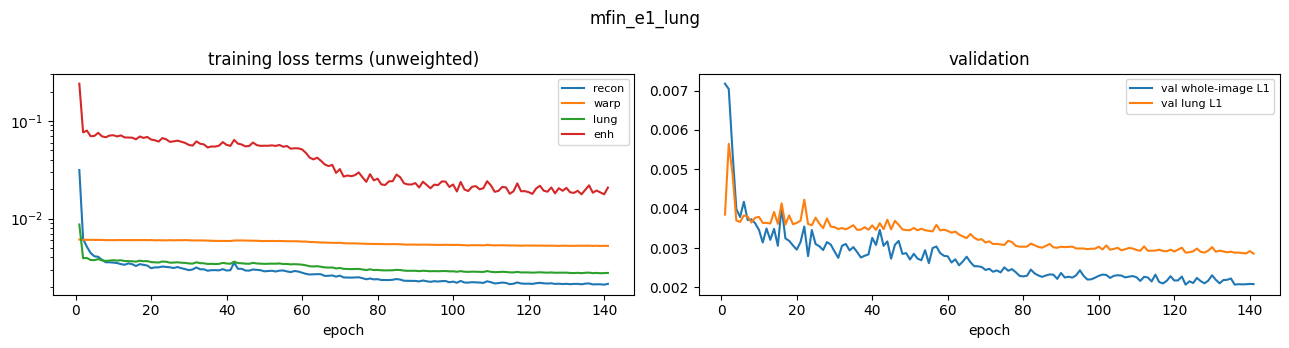

  -> lung L1 e1 0.00288 | curve RMSE e1 0.0180 | breath power ratio 0.98 | TV3 s4 PSE coarse/dense -2.78/-2.68 % | 24s
mfin_e1_lung_temp: model=mfin echo=e1 losses=w_recon=1.0, w_warp=0.5, w_lung=1.0, w_temporal=1.0
[mfin_e1_lung_temp] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_e1_lung_temp.pth (135 epochs)


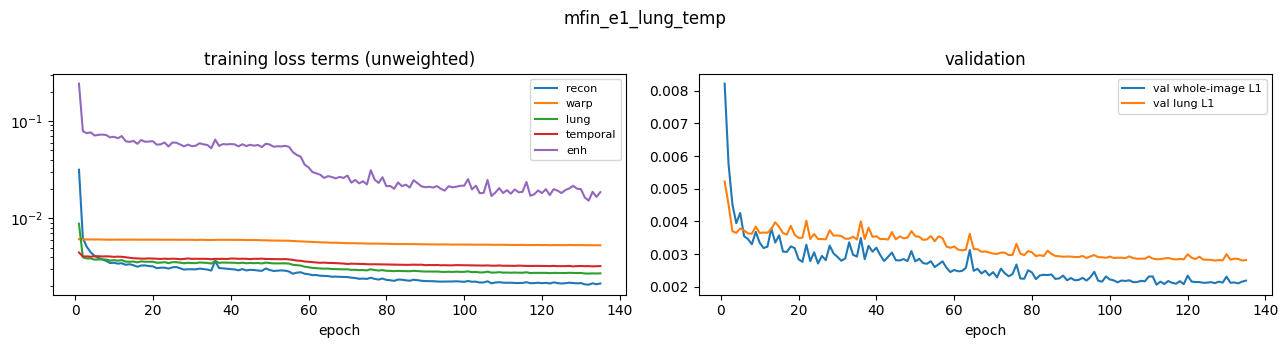

  -> lung L1 e1 0.00285 | curve RMSE e1 0.0156 | breath power ratio 1.00 | TV3 s4 PSE coarse/dense -2.78/-2.92 % | 24s
mfin_e1_full: model=mfin echo=e1 losses=w_recon=1.0, w_warp=0.5, w_lung=1.0, w_temporal=1.0, w_enh=0.1
[mfin_e1_full] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_e1_full.pth (141 epochs)


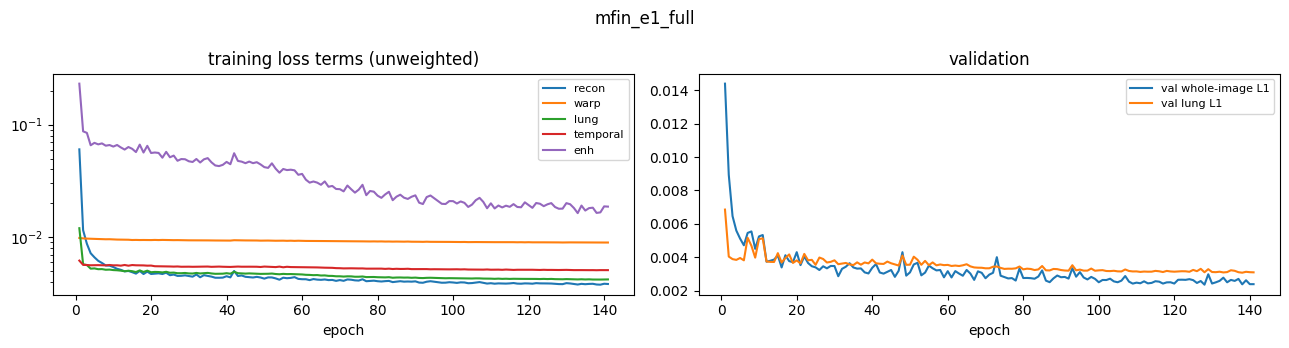

  -> lung L1 e1 0.00311 | curve RMSE e1 0.0205 | breath power ratio 1.14 | TV3 s4 PSE coarse/dense -2.78/-2.69 % | 24s
linear_e1e2: model=linear echo=e1e2 losses=w_recon=1.0, w_warp=0.5


  -> lung L1 e1 0.00358 | curve RMSE e1 0.0638 | breath power ratio 0.18 | TV3 s4 PSE coarse/dense -2.78/-2.81 % | 17s
mfin_me_e1e2_full: model=mfin_me echo=e1e2 losses=w_recon=1.0, w_warp=0.5, w_lung=1.0, w_temporal=1.0, w_enh=0.1, w_ratio=0.01
[mfin_me_e1e2_full] loaded checkpoint C:\edshkim98\phd\mina\checkpoints\mfin_me_e1e2_full.pth (157 epochs)


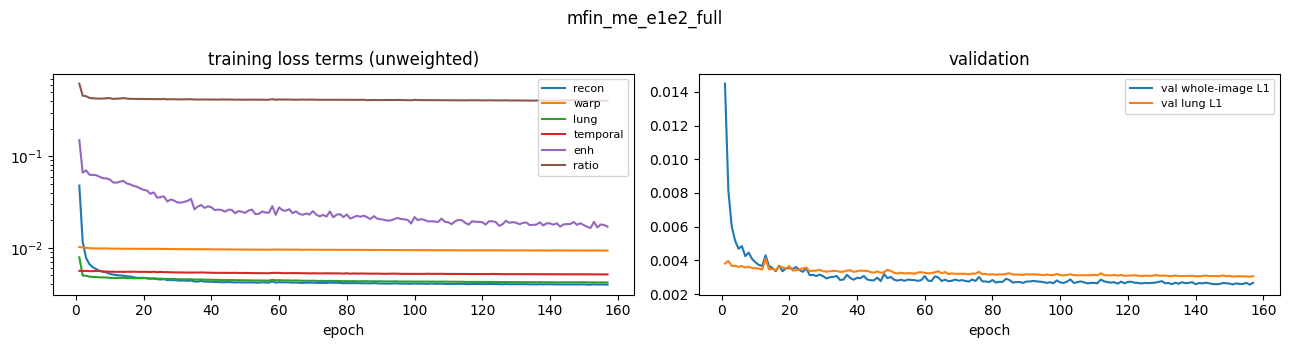

  -> lung L1 e1 0.00308 | curve RMSE e1 0.0176 | breath power ratio 1.08 | TV3 s4 PSE coarse/dense -2.78/-2.78 % | 34s


In [16]:
STAGE1 = 'checkpoints/stage1_100ep'          # first-pass checkpoints (100 epochs, patience 10) that the fine-tuning runs start from
def stage1(name): return f'{STAGE1}/{name}.pth'

FT = dict(patience=100)                       # fine-tuning / scratch runs: a fixed 100 epochs, no early stopping (best epoch is still kept)
EXPERIMENTS = [
    # ---- baselines: your previous models, echo 1 only, original loss -------------------------
    Config(name='linear_e1',      model='linear',    echo_mode='e1'),
    Config(name='unet_e1',        model='unet',      echo_mode='e1', w_warp=0.0),
    Config(name='mfin_base_e1',   model='mfin_base', echo_mode='e1'),
    Config(name='mfin_e1_scratch', model='mfin',     echo_mode='e1', **FT),
    # ---- loss ablations on the 1-echo time-conditioned MFIN (fine-tuned from the stage-1 checkpoints) ----
    Config(name='mfin_e1_lung',          model='mfin', w_lung=1.0, init_from=stage1('mfin_e1_lung'), **FT),
    Config(name='mfin_e1_lung_temp',     model='mfin', w_lung=1.0, w_temporal=1.0, n_time_samples=2,
                                         init_from=stage1('mfin_e1_lung_temp'), **FT),
    Config(name='mfin_e1_full',          model='mfin', w_lung=1.0, w_temporal=1.0, w_enh=0.1, n_time_samples=2,
                                         aug_flip=True, aug_intensity=0.05, aug_noise=0.003, init_from=stage1('mfin_e1_full'), **FT),
    # ---- two echoes --------------------------------------------------------------------------
    Config(name='linear_e1e2',    model='linear',  echo_mode='e1e2'),
    Config(name='mfin_me_e1e2_full', model='mfin_me', echo_mode='e1e2', w_lung=1.0, w_temporal=1.0, w_enh=0.1, w_ratio=0.01,
                                     n_time_samples=2, aug_flip=True, aug_intensity=0.05, aug_noise=0.003,
                                     init_from=stage1('mfin_me_e1e2_full'), **FT),
]
assert len({c.name for c in EXPERIMENTS}) == len(EXPERIMENTS), 'experiment names must be unique'
if SMOKE:                                    # the pipeline check trains everything from scratch for 2 epochs
    EXPERIMENTS = [replace(c, init_from='') for c in EXPERIMENTS]

MODELS, HISTORIES, VAL_DF, DENSE, TV3_OUT = {}, {}, {}, {}, {}
VAL_MAX_SAMPLES = 400 if SMOKE else None
TV3_RANGE = (0, 220) if SMOKE else None      # smoke: air + O2 phase only (enough for PSE and wash-in)

def append_registry(row):
    df = pd.DataFrame([row])
    if os.path.exists(REGISTRY_CSV):
        old = pd.read_csv(REGISTRY_CSV)
        df = pd.concat([old[old.name != row['name']], df], ignore_index=True)     # one row per experiment name (latest wins)
    df.to_csv(REGISTRY_CSV, index=False)

for cfg in EXPERIMENTS:
    cfg = apply_smoke(cfg)
    print('=' * 100); print(f"{cfg.name}: model={cfg.model} echo={cfg.echo_mode} losses=" +
          ", ".join(f"{k}={getattr(cfg, k)}" for k in ['w_recon', 'w_warp', 'w_lung', 'w_temporal', 'w_enh', 'w_ratio'] if getattr(cfg, k)))
    t0 = time.time()
    model, hist = get_or_train(cfg)
    if model is None:
        continue
    MODELS[cfg.name], HISTORIES[cfg.name] = model, hist
    plot_history(hist, cfg.name)

    VAL_DF[cfg.name] = evaluate_val(model, cfg, VAL_MAX_SAMPLES)
    dense_m, DENSE[cfg.name] = evaluate_dense_val(model, cfg)
    tv3_m, TV3_OUT[cfg.name] = {}, {}
    for sl in TV3_SLICES:
        m_sl, TV3_OUT[cfg.name][sl] = evaluate_tv3(model, cfg, TV3_RANGE, sl)
        tv3_m.update({f'{k}_s{sl}': v for k, v in m_sl.items()})

    row = dict(name=cfg.name, smoke=SMOKE, timestamp=time.strftime('%Y-%m-%d %H:%M'), params_M=n_params(model) / 1e6,
               epochs_run=len(hist), config=json.dumps(asdict(cfg)))
    row.update(summarize_val(VAL_DF[cfg.name])); row.update(dense_m); row.update(tv3_m)
    append_registry(row)
    print(f"  -> lung L1 e1 {row['l1_lung_e1']:.5f} | curve RMSE e1 {row['curve_rmse_e1']:.4f} | breath power ratio {row['breath_power_ratio_e1']:.2f} "
          f"| TV3 s{TV3_PRIMARY} PSE coarse/dense {row[f'pse_lung_coarse_e1_s{TV3_PRIMARY}']:.2f}/{row[f'pse_lung_dense_e1_s{TV3_PRIMARY}']:.2f} % "
          f"| {time.time()-t0:.0f}s")

# keep only the experiments of the current grid in the registry (removes rows of dropped configs)
_reg = pd.read_csv(REGISTRY_CSV)
_reg = _reg[_reg.name.isin([c.name for c in EXPERIMENTS])].dropna(axis=1, how='all')   # also drops columns of old metric names
_reg.to_csv(REGISTRY_CSV, index=False)

## 7. Results: tables and visual comparison

* **7a** headline tables and bar charts from the registry (lower is better for L1 / RMSE / MAD; power ratio and t-std ratio should be ~1).
* **7b** error vs. target position `rel_t` for every model.
* **7c** qualitative: truth / prediction / error map for a mid-gap sample, flows and blending mask of the MFIN models.
* **7d** dense validation curves: truth vs synthesised lung-mean signal and breathing spectrum.
* **7e** TV3 (primary slice): lung-mean curve coarse vs dense, PSE maps coarse vs dense, dR2\* maps coarse vs dense (2-echo models),
  and a PSE / dR2\* table for every evaluated slice.

Full results

[image metrics, fast validation block]


,params_M,epochs_run,l1_e1,l1_lung_e1,l1_lung_mid_e1,psnr_e1,ssim_e1,l1_lung_e2,ssim_e2
name,,,,,,,,,
linear_e1,0.00000,0,0.00248,0.00358,0.00383,35.28865,0.98414,NaN,NaN
unet_e1,3.34998,29,0.00244,0.00360,0.00362,35.82774,0.98392,NaN,NaN
mfin_base_e1,1.70685,53,0.00239,0.00344,0.00344,36.04063,0.98162,NaN,NaN
mfin_e1_scratch,1.70786,100,0.00219,0.00311,0.00325,37.97309,0.98255,NaN,NaN
mfin_e1_lung,1.70786,141,0.00207,0.00288,0.00298,38.29789,0.98497,NaN,NaN
mfin_e1_lung_temp,1.70786,135,0.00207,0.00285,0.00292,38.36575,0.98429,NaN,NaN
mfin_e1_full,1.70786,141,0.00237,0.00311,0.00322,37.17049,0.98113,NaN,NaN
linear_e1e2,0.00000,0,0.00248,0.00358,0.00383,35.28865,0.98414,0.00338,0.97596
mfin_me_e1e2_full,1.70860,157,0.00230,0.00308,0.00320,37.37666,0.98315,0.00298,0.97446



[dynamics, dense 26x reconstruction of the validation block]


,curve_rmse_e1,breath_power_ratio_e1,tstd_ratio_e1,r2s_curve_rmse
name,,,,
linear_e1,0.064,0.177,0.690,NaN
unet_e1,0.055,0.231,0.566,NaN
mfin_base_e1,0.053,0.318,0.569,NaN
mfin_e1_scratch,0.023,0.804,0.733,NaN
mfin_e1_lung,0.018,0.984,0.757,NaN
mfin_e1_lung_temp,0.016,0.999,0.773,NaN
mfin_e1_full,0.020,1.142,0.766,NaN
linear_e1e2,0.064,0.177,0.690,42.986
mfin_me_e1e2_full,0.018,1.077,0.750,39.858



[TV3 clinical scan, slice 4: PSE (%) and dR2* (1/s), coarse vs dense - consistency check, no dense ground truth]


,pse_lung_coarse_e1_s4,pse_lung_dense_e1_s4,pse_vox_coarse_e1_s4,pse_vox_dense_e1_s4,pse_map_mad_e1_s4,dr2s_roi_coarse_s4,dr2s_roi_dense_s4,dr2s_map_mad_s4,pse_lung_dense_e2_s4,pse_map_mad_e2_s4
name,,,,,,,,,,
linear_e1,-2.783,-2.809,-4.557,-4.600,0.106,NaN,NaN,NaN,NaN,NaN
unet_e1,-2.783,-1.644,-4.557,-2.085,4.126,NaN,NaN,NaN,NaN,NaN
mfin_base_e1,-2.783,-2.621,-4.557,-4.009,1.709,NaN,NaN,NaN,NaN,NaN
mfin_e1_scratch,-2.783,-2.872,-4.557,-4.639,0.474,NaN,NaN,NaN,NaN,NaN
mfin_e1_lung,-2.783,-2.679,-4.557,-4.276,0.674,NaN,NaN,NaN,NaN,NaN
mfin_e1_lung_temp,-2.783,-2.915,-4.557,-4.531,0.734,NaN,NaN,NaN,NaN,NaN
mfin_e1_full,-2.783,-2.690,-4.557,-4.267,0.771,NaN,NaN,NaN,NaN,NaN
linear_e1e2,-2.783,-2.809,-4.557,-4.600,0.106,31.138,31.538,3.606,-4.329,0.183
mfin_me_e1e2_full,-2.783,-2.780,-4.557,-4.468,0.830,31.138,30.692,39.015,-4.254,1.829



[TV3 wash-in tau (s), slice 4 - diagnostic only: 300 = no saturating wash-in could be fitted]


,washin_tau_coarse_e1_s4,washin_tau_dense_e1_s4
name,,
linear_e1,16.5,16.8
unet_e1,16.5,16.7
mfin_base_e1,16.5,16.9
mfin_e1_scratch,16.5,17.0
mfin_e1_lung,16.5,16.0
mfin_e1_lung_temp,16.5,17.6
mfin_e1_full,16.5,16.6
linear_e1e2,16.5,16.8
mfin_me_e1e2_full,16.5,16.6


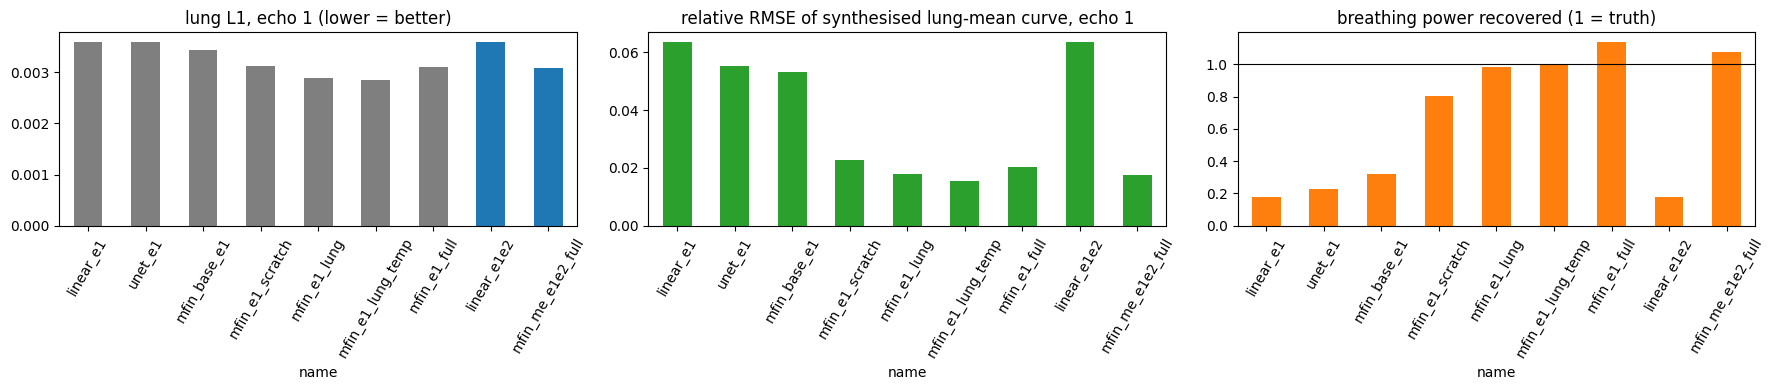

In [17]:
# ---- 7a. summary tables and bar charts --------------------------------------------------------------------------
reg = pd.read_csv(REGISTRY_CSV)
reg = reg[reg.name.isin([c.name for c in EXPERIMENTS])].set_index('name').loc[[c.name for c in EXPERIMENTS if c.name in MODELS]]
cols_img = ['params_M', 'epochs_run', 'l1_e1', 'l1_lung_e1', 'l1_lung_mid_e1', 'psnr_e1', 'ssim_e1', 'l1_lung_e2', 'ssim_e2']
cols_dyn = ['curve_rmse_e1', 'breath_power_ratio_e1', 'tstd_ratio_e1', 'r2s_curve_rmse']
P = f'_s{TV3_PRIMARY}'
cols_tv3 = [c + P for c in ['pse_lung_coarse_e1', 'pse_lung_dense_e1', 'pse_vox_coarse_e1', 'pse_vox_dense_e1', 'pse_map_mad_e1', 'dr2s_roi_coarse', 'dr2s_roi_dense', 'dr2s_map_mad']] + [c + P for c in [
            'pse_lung_dense_e2', 'pse_map_mad_e2']]
print('SMOKE MODE: numbers below come from 2-epoch models and are only a pipeline check' if SMOKE else 'Full results')
print('\n[image metrics, fast validation block]'); display(reg[[c for c in cols_img if c in reg]].round(5))
print('\n[dynamics, dense 26x reconstruction of the validation block]'); display(reg[[c for c in cols_dyn if c in reg]].round(3))
print(f'\n[TV3 clinical scan, slice {TV3_PRIMARY}: PSE (%) and dR2* (1/s), coarse vs dense - consistency check, no dense ground truth]')
display(reg[[c for c in cols_tv3 if c in reg]].round(3))
print(f'\n[TV3 wash-in tau (s), slice {TV3_PRIMARY} - diagnostic only: 300 = no saturating wash-in could be fitted]')
display(reg[[c for c in [f'washin_tau_coarse_e1{P}', f'washin_tau_dense_e1{P}'] if c in reg]].round(1))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
reg['l1_lung_e1'].plot.bar(ax=ax[0], color=['tab:gray' if 'e1e2' not in n else 'tab:blue' for n in reg.index]); ax[0].set_title('lung L1, echo 1 (lower = better)')
reg['curve_rmse_e1'].plot.bar(ax=ax[1], color='tab:green'); ax[1].set_title('relative RMSE of synthesised lung-mean curve, echo 1')
reg['breath_power_ratio_e1'].plot.bar(ax=ax[2], color='tab:orange'); ax[2].axhline(1, color='k', lw=0.8); ax[2].set_title('breathing power recovered (1 = truth)')
for a in ax: a.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

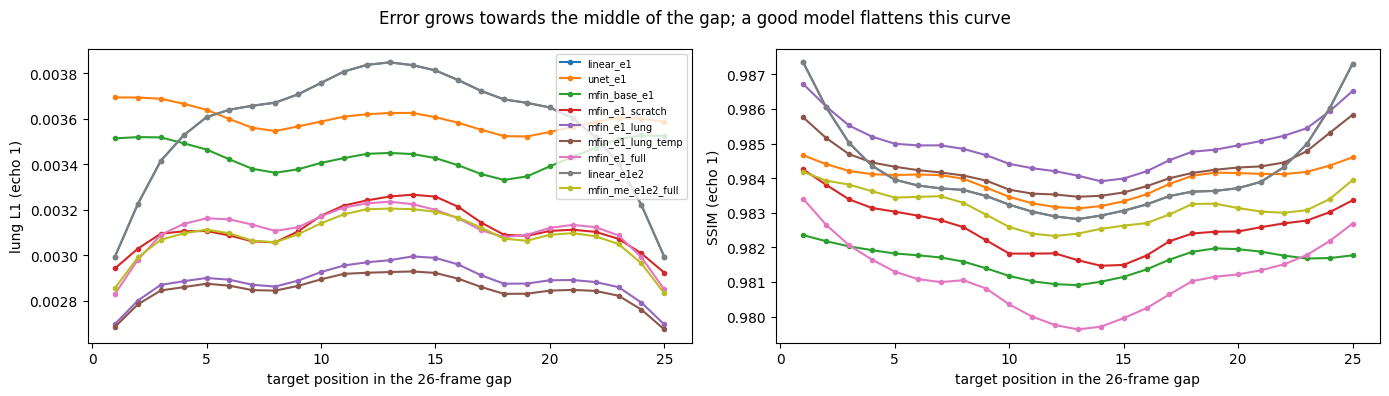

In [18]:
# ---- 7b. error vs target position ---------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, df in VAL_DF.items():
    g = df[df.echo == 1].groupby(((df.rel_t * 26).round()).astype(int)).l1_lung.mean()
    ax[0].plot(g.index, g.values, marker='.', label=name)
    g = df[df.echo == 1].groupby(((df.rel_t * 26).round()).astype(int)).ssim.mean()
    ax[1].plot(g.index, g.values, marker='.', label=name)
ax[0].set_xlabel('target position in the 26-frame gap'); ax[0].set_ylabel('lung L1 (echo 1)'); ax[0].legend(fontsize=7)
ax[1].set_xlabel('target position in the 26-frame gap'); ax[1].set_ylabel('SSIM (echo 1)')
plt.suptitle('Error grows towards the middle of the gap; a good model flattens this curve'); plt.tight_layout(); plt.show()

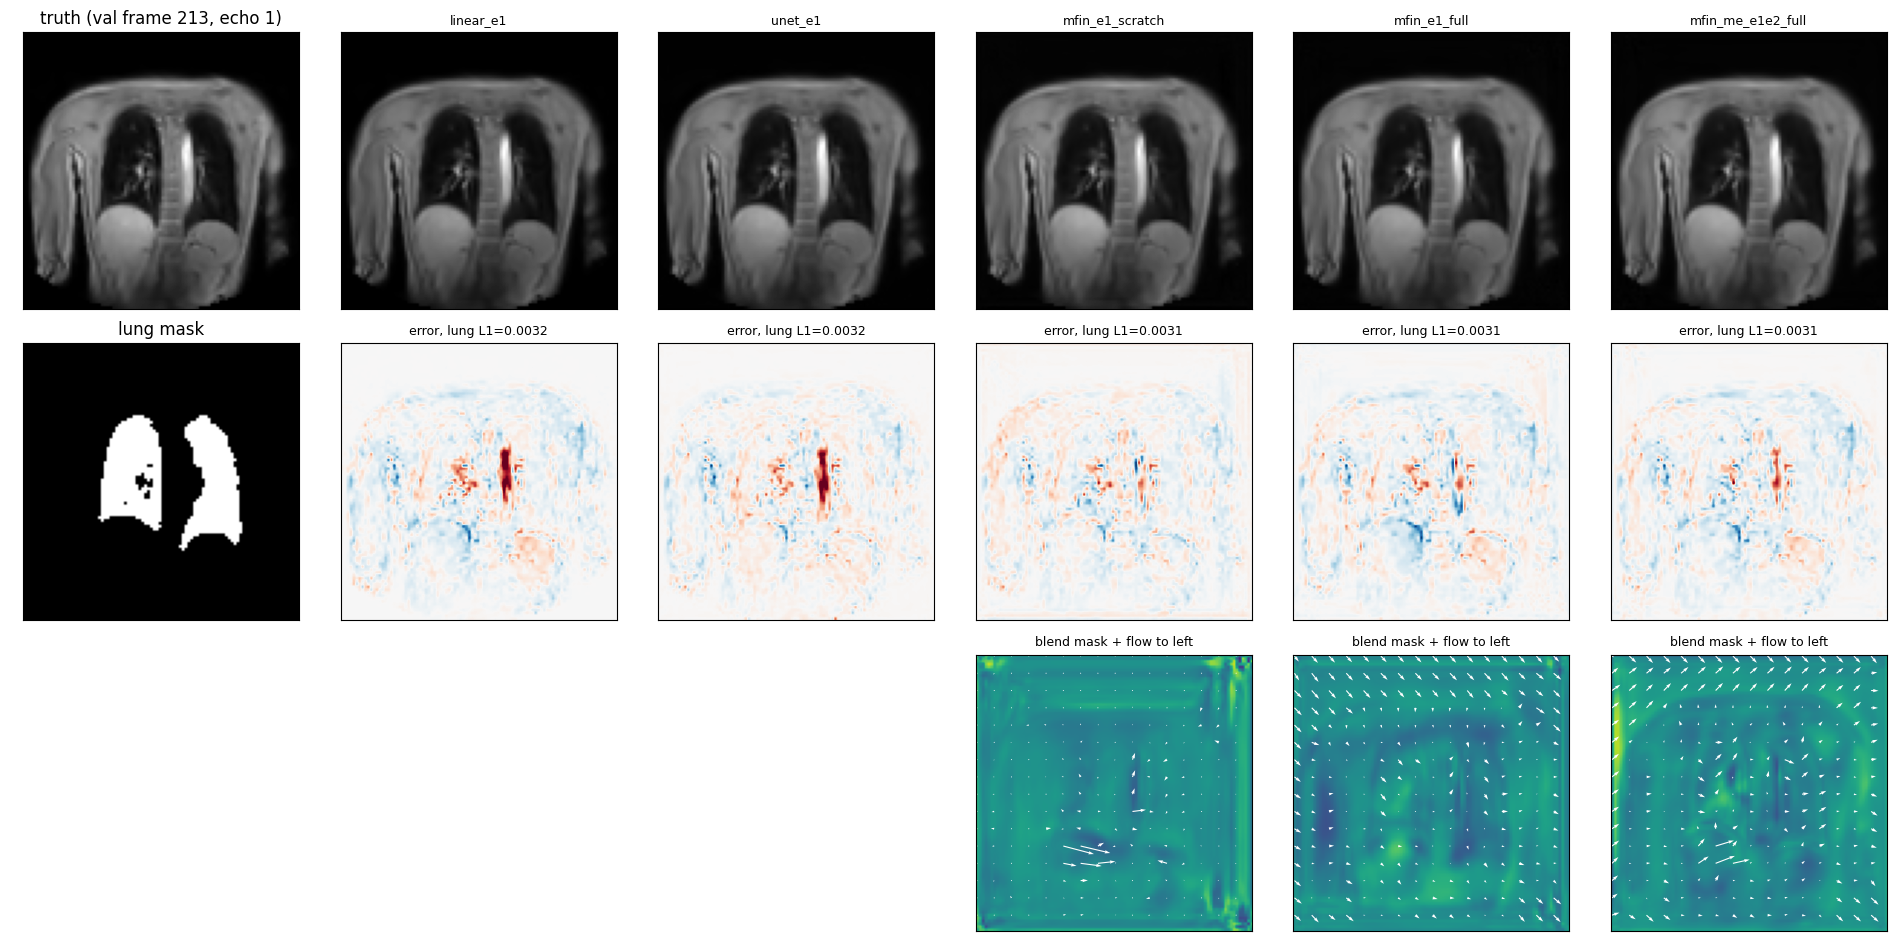

In [19]:
# ---- 7c. qualitative comparison at rel_t = 0.5 ---------------------------------------------------
show = [n for n in ['linear_e1', 'unet_e1', 'mfin_e1_scratch', 'mfin_e1_full', 'mfin_me_e1e2_full'] if n in MODELS]
i = 200; j = i + 26; k = i + 13           # a validation pair (indices within FAST_VAL)
fig, ax = plt.subplots(3, len(show) + 1, figsize=(3.2 * (len(show) + 1), 9.5))
cfg0 = Config(echo_mode='e1'); div0 = resolve_norm_div(cfg0)
truth = FAST_VAL[k, 0] / div0
ax[0, 0].imshow(disp(truth), cmap='gray'); ax[0, 0].set_title(f'truth (val frame {k}, echo 1)')
ax[1, 0].imshow(disp(MASK_FAST), cmap='gray'); ax[1, 0].set_title('lung mask')
ax[2, 0].axis('off')
for col, name in enumerate(show, start=1):
    cfg = apply_smoke(next(c for c in EXPERIMENTS if c.name == name)); C = cfg.n_echo; div = resolve_norm_div(cfg)
    x = np.concatenate([select_echo(FAST_VAL, cfg)[i], select_echo(FAST_VAL, cfg)[j]], 0)[None] / div
    with torch.no_grad():
        o = run_model(MODELS[name], cfg, torch.tensor(x, dtype=torch.float32).to(DEVICE), torch.tensor([0.5]).to(DEVICE),
                      torch.tensor([FAST_DT_MS * 26 / cfg.target_dt_ms]).to(DEVICE))
    p = o['pred'][0, 0].cpu().numpy() * div / div0
    ax[0, col].imshow(disp(p), cmap='gray'); ax[0, col].set_title(name, fontsize=9)
    im = ax[1, col].imshow(disp(p - truth), cmap='RdBu_r', vmin=-0.03, vmax=0.03); ax[1, col].set_title(f'error, lung L1={np.abs(p-truth)[MASK_FAST].mean():.4f}', fontsize=9)
    if o['flows'] is not None:
        fl = o['flows'][0][0].cpu().numpy(); mk = o['mask'][0, 0].cpu().numpy()
        ax[2, col].imshow(disp(mk), cmap='viridis', vmin=0, vmax=1)
        yy, xx = np.mgrid[0:96:6, 0:96:6]
        flr = np.stack([disp(fl[0]), disp(fl[1])])
        ax[2, col].quiver(xx, yy, flr[0][::6, ::6], -flr[1][::6, ::6], color='w', scale=20, width=0.004)
        ax[2, col].set_title('blend mask + flow to left', fontsize=9)
    else:
        ax[2, col].axis('off')
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

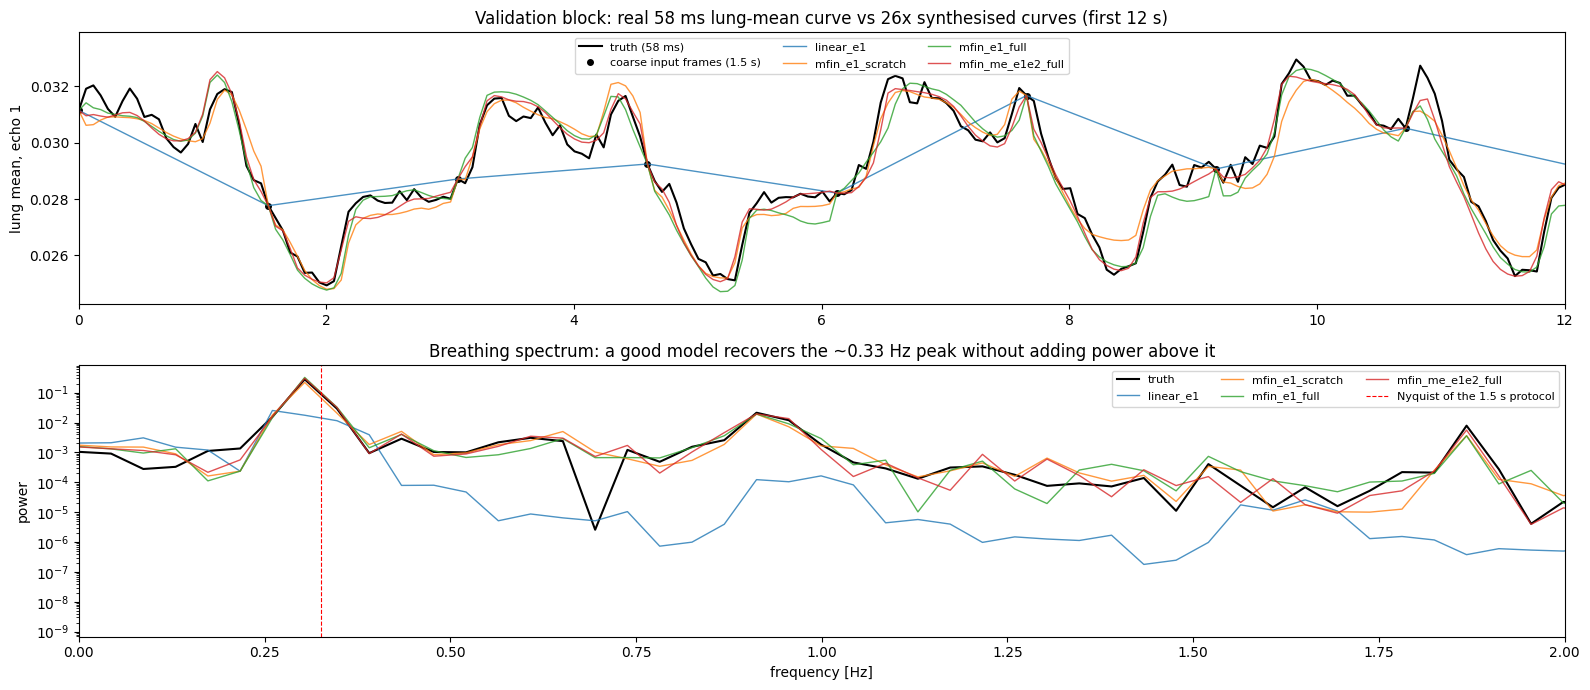

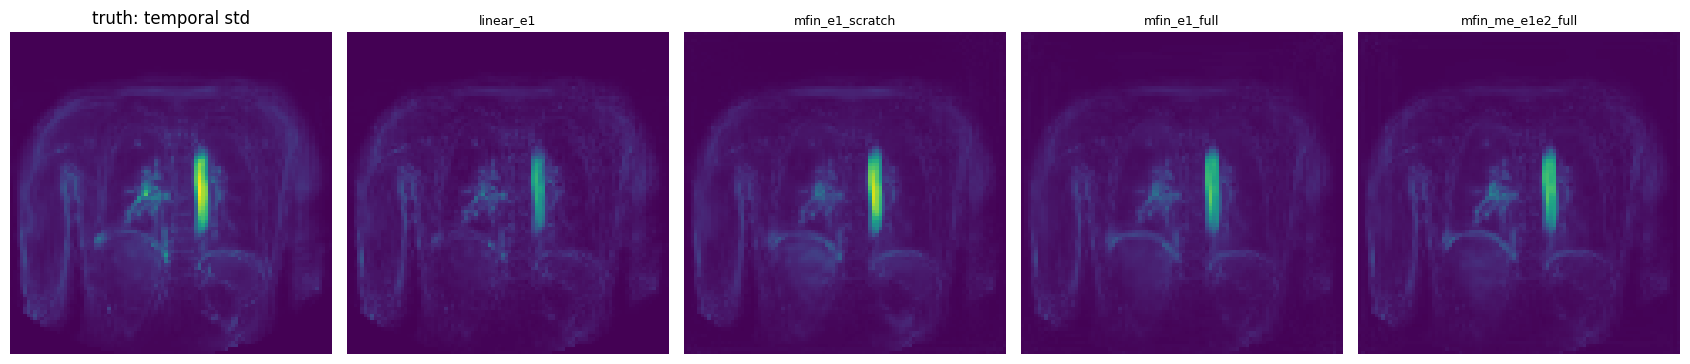

In [20]:
# ---- 7d. dense validation curves ------------------------------------------------------------------
show = [n for n in ['linear_e1', 'mfin_e1_scratch', 'mfin_e1_full', 'mfin_me_e1e2_full'] if n in DENSE]
t = np.arange(DENSE[show[0]]['dense'].shape[0]) * FAST_DT_MS / 1000
fig, ax = plt.subplots(2, 1, figsize=(16, 7))
ct = DENSE[show[0]]['curve_truth'][:, 0]
ax[0].plot(t, ct, 'k', lw=1.5, label='truth (58 ms)')
ax[0].plot(t[::26], ct[::26], 'ko', ms=4, label='coarse input frames (1.5 s)')
for n in show:
    ax[0].plot(t, DENSE[n]['curve_dense'][:, 0], lw=1, alpha=0.8, label=n)
ax[0].set_xlim(0, 12); ax[0].set_ylabel('lung mean, echo 1'); ax[0].legend(fontsize=8, ncol=3); ax[0].set_title('Validation block: real 58 ms lung-mean curve vs 26x synthesised curves (first 12 s)')
f = np.fft.rfftfreq(len(ct), FAST_DT_MS / 1000)
def spec(c): c = c - ndi.uniform_filter1d(c, 85, mode='nearest'); return np.abs(np.fft.rfft(c)) ** 2
ax[1].semilogy(f, spec(ct), 'k', lw=1.5, label='truth')
for n in show: ax[1].semilogy(f, spec(DENSE[n]['curve_dense'][:, 0]), lw=1, alpha=0.8, label=n)
ax[1].axvline(1 / (26 * FAST_DT_MS / 1000) / 2, color='r', ls='--', lw=0.8, label='Nyquist of the 1.5 s protocol')
ax[1].set_xlim(0, 2); ax[1].set_xlabel('frequency [Hz]'); ax[1].set_ylabel('power'); ax[1].legend(fontsize=8, ncol=3)
ax[1].set_title('Breathing spectrum: a good model recovers the ~0.33 Hz peak without adding power above it')
plt.tight_layout(); plt.show()

# pixel-wise temporal std maps (truth vs models) - shows where motion/dynamics are reproduced
fig, ax = plt.subplots(1, len(show) + 1, figsize=(3.4 * (len(show) + 1), 3.6))
vmax = DENSE[show[0]]['truth'][:, 0].std(0).max()
ax[0].imshow(disp(DENSE[show[0]]['truth'][:, 0].std(0)), vmin=0, vmax=vmax); ax[0].set_title('truth: temporal std')
for a, n in zip(ax[1:], show):
    a.imshow(disp(DENSE[n]['dense'][:, 0].std(0)), vmin=0, vmax=vmax); a.set_title(n, fontsize=9)
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

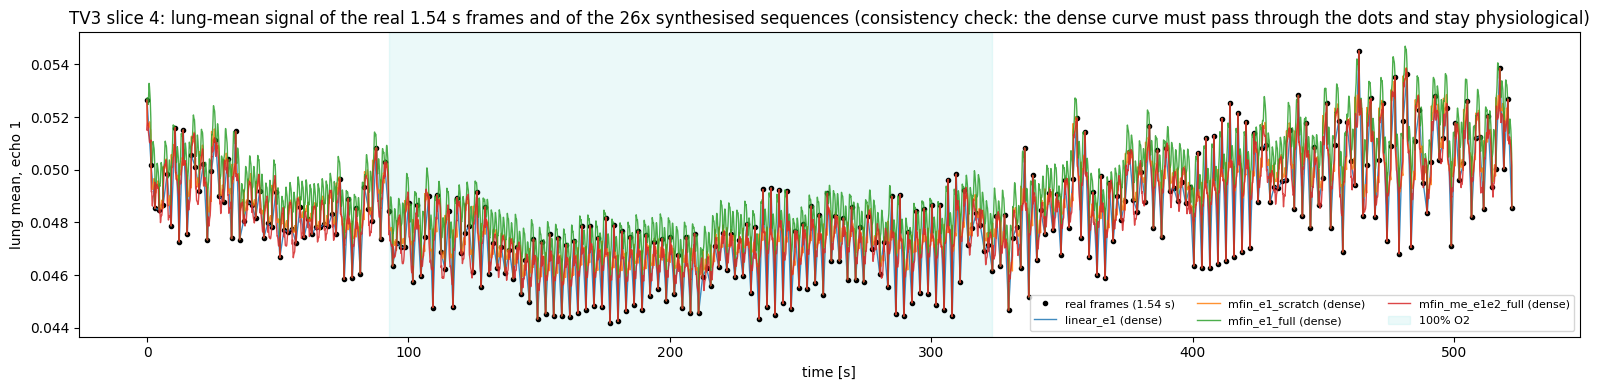

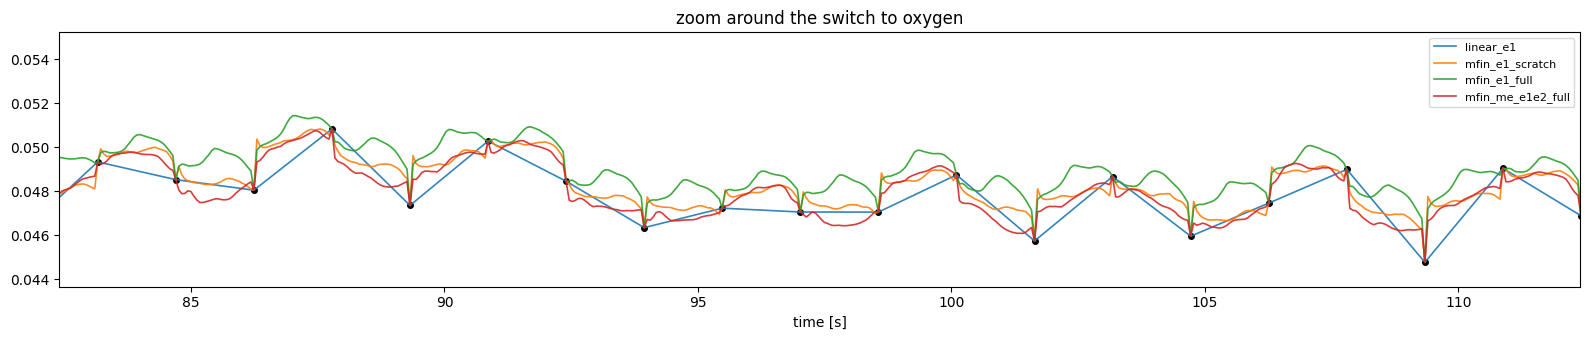

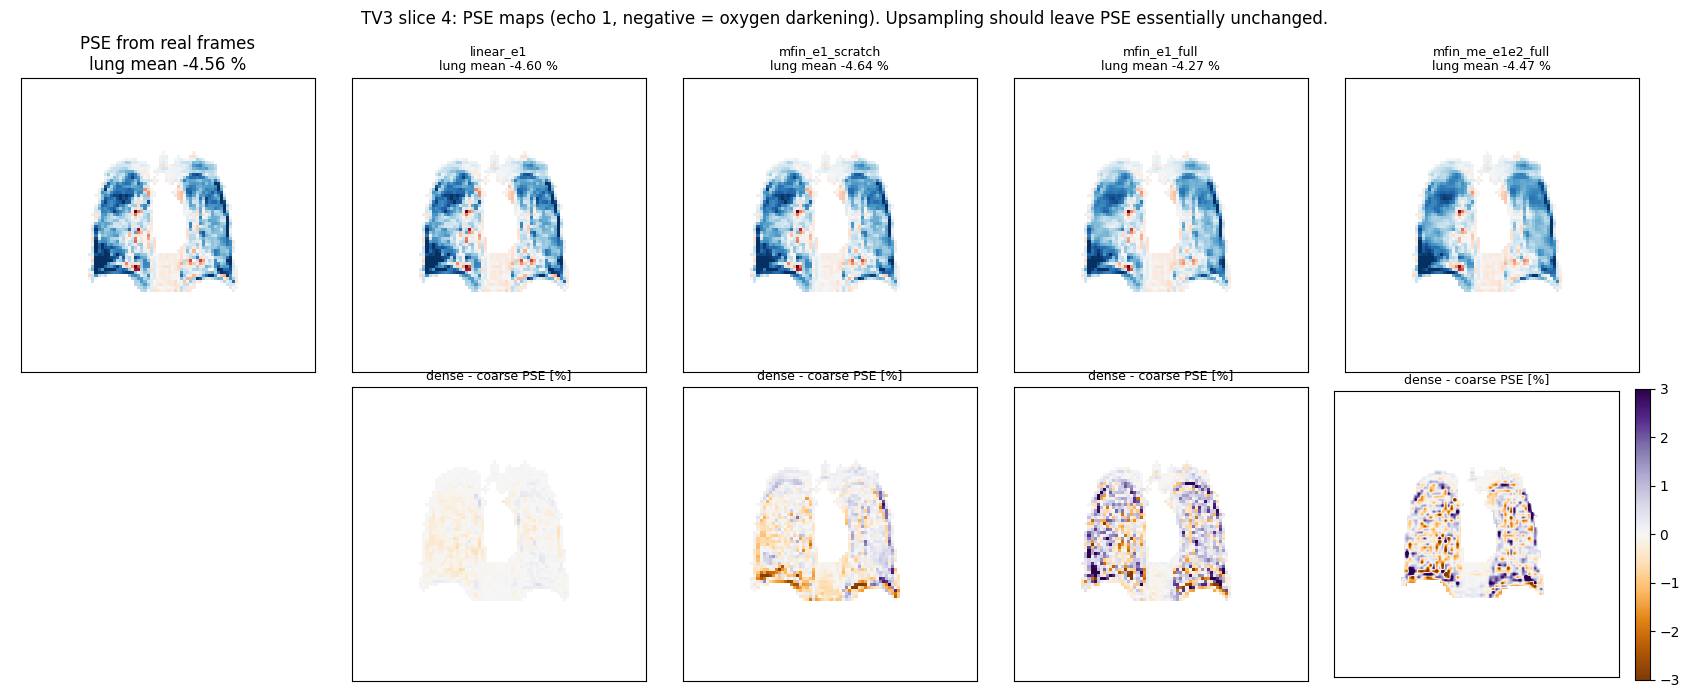

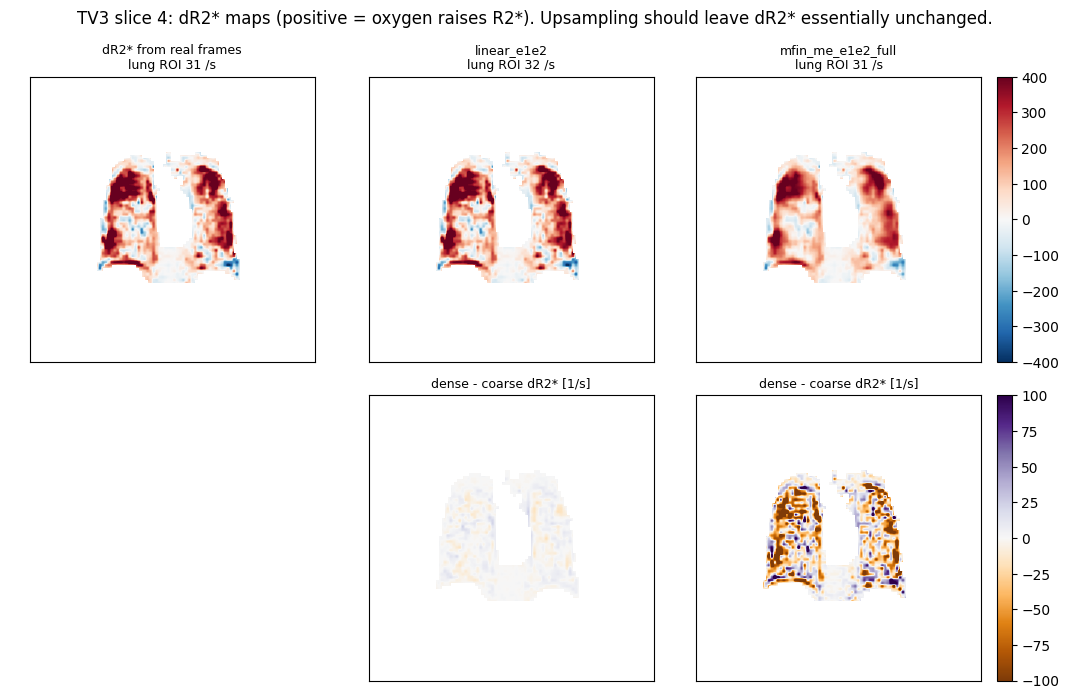


[TV3 slice 4: PSE (%) and dR2* (1/s), coarse vs dense]


,pse_lung_coarse_e1_s4,pse_lung_dense_e1_s4,pse_vox_coarse_e1_s4,pse_vox_dense_e1_s4,pse_map_mad_e1_s4,dr2s_roi_coarse_s4,dr2s_roi_dense_s4,dr2s_map_mad_s4
name,,,,,,,,
linear_e1,-2.78,-2.81,-4.56,-4.60,0.11,NaN,NaN,NaN
unet_e1,-2.78,-1.64,-4.56,-2.09,4.13,NaN,NaN,NaN
mfin_base_e1,-2.78,-2.62,-4.56,-4.01,1.71,NaN,NaN,NaN
mfin_e1_scratch,-2.78,-2.87,-4.56,-4.64,0.47,NaN,NaN,NaN
mfin_e1_lung,-2.78,-2.68,-4.56,-4.28,0.67,NaN,NaN,NaN
mfin_e1_lung_temp,-2.78,-2.92,-4.56,-4.53,0.73,NaN,NaN,NaN
mfin_e1_full,-2.78,-2.69,-4.56,-4.27,0.77,NaN,NaN,NaN
linear_e1e2,-2.78,-2.81,-4.56,-4.60,0.11,31.14,31.54,3.61
mfin_me_e1e2_full,-2.78,-2.78,-4.56,-4.47,0.83,31.14,30.69,39.02



[TV3 slice 3: PSE (%) and dR2* (1/s), coarse vs dense]


,pse_lung_coarse_e1_s3,pse_lung_dense_e1_s3,pse_vox_coarse_e1_s3,pse_vox_dense_e1_s3,pse_map_mad_e1_s3,dr2s_roi_coarse_s3,dr2s_roi_dense_s3,dr2s_map_mad_s3
name,,,,,,,,
linear_e1,-1.35,-1.37,-3.7,-3.74,0.13,NaN,NaN,NaN
unet_e1,-1.35,-0.90,-3.7,-1.28,4.47,NaN,NaN,NaN
mfin_base_e1,-1.35,-1.16,-3.7,-2.97,1.86,NaN,NaN,NaN
mfin_e1_scratch,-1.35,-1.36,-3.7,-3.75,0.48,NaN,NaN,NaN
mfin_e1_lung,-1.35,-1.38,-3.7,-3.47,0.87,NaN,NaN,NaN
mfin_e1_lung_temp,-1.35,-1.47,-3.7,-3.59,0.83,NaN,NaN,NaN
mfin_e1_full,-1.35,-1.29,-3.7,-3.32,1.05,NaN,NaN,NaN
linear_e1e2,-1.35,-1.37,-3.7,-3.74,0.13,5.11,5.07,4.54
mfin_me_e1e2_full,-1.35,-1.42,-3.7,-3.64,1.06,5.11,4.94,46.89


In [21]:
# ---- 7e. TV3 clinical scan: curves, PSE maps, wash-in --------------------------------------------
show = [n for n in ['linear_e1', 'mfin_e1_scratch', 'mfin_e1_full', 'mfin_me_e1e2_full'] if n in TV3_OUT]
TV3_OUT_P = {n: TV3_OUT[n][TV3_PRIMARY] for n in TV3_OUT}       # primary slice only in the plots below
o0 = TV3_OUT_P[show[0]]
fig, ax = plt.subplots(1, 1, figsize=(16, 4))
ax.plot(o0['t_coarse'], o0['curve_coarse'][:, 0], 'ko', ms=3, label='real frames (1.54 s)')
for n in show:
    ax.plot(TV3_OUT_P[n]['t_dense'], TV3_OUT_P[n]['curve_dense'][:, 0], lw=1, alpha=0.85, label=n + ' (dense)')
for key, col in [('o2', 'c')]:
    ax.axvspan(TV3_GAS[key][0] * TV3_DT_MS / 1000, TV3_GAS[key][1] * TV3_DT_MS / 1000, color=col, alpha=0.08, label='100% O2')
ax.set_xlabel('time [s]'); ax.set_ylabel('lung mean, echo 1'); ax.legend(fontsize=8, ncol=3)
ax.set_title(f'TV3 slice {TV3_PRIMARY}: lung-mean signal of the real 1.54 s frames and of the 26x synthesised sequences (consistency check: the dense curve must pass through the dots and stay physiological)')
plt.tight_layout(); plt.show()

# zoom on 20 s around the gas switch to see what the models put between the real frames
fig, ax = plt.subplots(1, 1, figsize=(16, 3.5))
t_on = TV3_GAS['o2'][0] * TV3_DT_MS / 1000
ax.plot(o0['t_coarse'], o0['curve_coarse'][:, 0], 'ko', ms=4)
for n in show: ax.plot(TV3_OUT_P[n]['t_dense'], TV3_OUT_P[n]['curve_dense'][:, 0], lw=1.2, alpha=0.9, label=n)
ax.set_xlim(t_on - 10, t_on + 20); ax.legend(fontsize=8); ax.set_title('zoom around the switch to oxygen'); ax.set_xlabel('time [s]')
plt.tight_layout(); plt.show()

# PSE maps: coarse vs dense for each model
fig, ax = plt.subplots(2, len(show) + 1, figsize=(3.4 * (len(show) + 1), 7))
pc = o0['maps']['pse_coarse_e1']
ax[0, 0].imshow(disp(np.where(MASK_TV3, pc, np.nan)), cmap='RdBu_r', vmin=-15, vmax=15); ax[0, 0].set_title(f'PSE from real frames\nlung mean {pc[MASK_TV3].mean():.2f} %')
ax[1, 0].axis('off')
for col, n in enumerate(show, start=1):
    pdn = TV3_OUT_P[n]['maps']['pse_dense_e1']
    ax[0, col].imshow(disp(np.where(MASK_TV3, pdn, np.nan)), cmap='RdBu_r', vmin=-15, vmax=15); ax[0, col].set_title(f'{n}\nlung mean {pdn[MASK_TV3].mean():.2f} %', fontsize=9)
    im = ax[1, col].imshow(disp(np.where(MASK_TV3, pdn - pc, np.nan)), cmap='PuOr', vmin=-3, vmax=3); ax[1, col].set_title('dense - coarse PSE [%]', fontsize=9)
plt.colorbar(im, ax=ax[1, -1], fraction=0.046)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle(f'TV3 slice {TV3_PRIMARY}: PSE maps (echo 1, negative = oxygen darkening). Upsampling should leave PSE essentially unchanged.'); plt.tight_layout(); plt.show()

# dR2* maps (2-echo models only): coarse vs dense
show2 = [n for n in ['linear_e1e2', 'mfin_me_e1e2_full'] if n in TV3_OUT and 'dr2s_coarse' in TV3_OUT_P[n]['maps']]
if show2:
    dc = TV3_OUT_P[show2[0]]['maps']['dr2s_coarse']
    fig, ax = plt.subplots(2, len(show2) + 1, figsize=(3.6 * (len(show2) + 1), 7))
    im0 = ax[0, 0].imshow(disp(np.where(MASK_TV3, dc, np.nan)), cmap='RdBu_r', vmin=-400, vmax=400)
    ax[0, 0].set_title(f'dR2* from real frames\nlung ROI {reg.loc[show2[0], f"dr2s_roi_coarse_s{TV3_PRIMARY}"]:.0f} /s', fontsize=9); ax[1, 0].axis('off')
    for col, n in enumerate(show2, start=1):
        dd = TV3_OUT_P[n]['maps']['dr2s_dense']
        ax[0, col].imshow(disp(np.where(MASK_TV3, dd, np.nan)), cmap='RdBu_r', vmin=-400, vmax=400)
        ax[0, col].set_title(f'{n}\nlung ROI {reg.loc[n, f"dr2s_roi_dense_s{TV3_PRIMARY}"]:.0f} /s', fontsize=9)
        im = ax[1, col].imshow(disp(np.where(MASK_TV3, dd - dc, np.nan)), cmap='PuOr', vmin=-100, vmax=100); ax[1, col].set_title('dense - coarse dR2* [1/s]', fontsize=9)
    plt.colorbar(im0, ax=ax[0, -1], fraction=0.046); plt.colorbar(im, ax=ax[1, -1], fraction=0.046)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    plt.suptitle(f'TV3 slice {TV3_PRIMARY}: dR2* maps (positive = oxygen raises R2*). Upsampling should leave dR2* essentially unchanged.'); plt.tight_layout(); plt.show()

# PSE and dR2* for every evaluated slice (coarse vs dense)
for sl in TV3_SLICES:
    cols = [f'pse_lung_coarse_e1_s{sl}', f'pse_lung_dense_e1_s{sl}', f'pse_vox_coarse_e1_s{sl}', f'pse_vox_dense_e1_s{sl}', f'pse_map_mad_e1_s{sl}',
            f'dr2s_roi_coarse_s{sl}', f'dr2s_roi_dense_s{sl}', f'dr2s_map_mad_s{sl}']
    print(f'\n[TV3 slice {sl}: PSE (%) and dR2* (1/s), coarse vs dense]')
    display(reg[[c for c in cols if c in reg]].round(2))

## Notes and next steps

* **Smoke vs full.** With `SMOKE = False` the grid trains the baselines for up to 100 epochs with early stopping, trains
  `mfin_e1_scratch` for a fixed 100 epochs and fine-tunes the loss variants for a fixed 100 epochs on top of their stage-1
  checkpoints. Checkpoints are reused, so rerunning only trains new or changed configs (change the `name` when you change a config).
* **Headline comparisons to make:** (1) `mfin_e1_scratch` vs `mfin_e1_lung` vs `mfin_e1_lung_temp` vs `mfin_e1_full` isolates
  the new loss terms, with the caveat that the fine-tuned models have seen more epochs in total (stage 1 + 100) than the scratch
  control (100); (2) `mfin_e1_full` vs `mfin_me_e1e2_full` isolates the second echo (identical losses and schedule);
  (3) `linear_e1e2` vs `mfin_me_e1e2_full` on `r2s_curve_rmse` tells you whether the network preserves R2\* better than
  linear interpolation does.
* **Models without time input** (`unet`, `mfin_base`) return one frame per pair, so their dense reconstruction repeats that
  frame across the gap and their 7b curves are flat. A midpoint-only evaluation (as in the original notebook) or recursive
  bisection would be the fairer way to use them.
* **Data.** Everything is one subject and one slice; the validation block is the last 24 s of the same scan. Any claim about
  generalisation needs a second fast scan held out entirely (`0401` is the same subject 10 minutes earlier; it is a reasonable
  first test once its registered version exists).
* **Why the TV3 curve zig-zags.** The real 1.54 s lung-mean curve alternates frame to frame: breathing (~0.33 Hz) sits at the
  Nyquist limit of the protocol and is aliased. That zig-zag is exactly the information the 26x reconstruction is meant to
  recover, so a plausible dense curve should show a smooth ~3 s oscillation through the dots, not independent spikes.
* **Gas state of the fast scans** must be confirmed from the scan log before interpreting any oxygen effect in the training data.